# The 9-bus formulation and configuration, with a sandbox

This first notebook of the repository orients the reader to the formulation and the configuration that the workshop notebooks share. Each workshop notebook clears the same engine on the same WSCC 9-bus case and sets its own values in its own `# -- EDIT --` cell.

The formulation section states the program every clearing solves, the prices and rents it produces and the allocations of the rent. The configuration section sets every knob of the case in one cell, from the ratings, the fleet and the loads to one market or two independent markets on the same network, the footprints, the line sets, the schedules and bids, the tags and the ledgers. The notebook clears one period, energy only, on a lossless DC network. The stored runs are Example 1, the canonical anchor at the defaults, and Example 2, two markets with a scheduling point at bus 8 under a 100 MW intertie scheduling limit.

The closing sandbox reruns the whole chain on whatever the configuration cell sets, so a reader changes a knob there, reruns the notebook and reads what moved.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pdockery/wscc9-illustrative-model/blob/main/101_sandbox.ipynb)

In [1]:
#@title ▶ Run me first: Colab setup (installs packages, fetches the library)
# On Google Colab this installs the packages Colab lacks and downloads the
# library modules into lib/. Run locally, it walks up from the working
# directory to the folder that holds lib/seams_engine.py.
import pathlib
import subprocess
import sys

LIB_MODULES = (
    "seams_engine", "wscc9_model", "ieee9_network", "nodal_plot",
    "wscc9_figures", "seam_views", "etag", "risk", "revenue_allocation",
    "atc", "bilateral", "footprints", "intertie", "lab_types",
)


def _sh(cmd: str) -> None:
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main/lib"
    _lib = pathlib.Path("lib").resolve()
    _lib.mkdir(exist_ok=True)
    for _m in LIB_MODULES:
        _sh(f"wget -q {_base}/{_m}.py -O {_lib / (_m + '.py')}")
    print("Colab setup complete.")
else:
    _r = pathlib.Path.cwd().resolve()
    while not (_r / "lib" / "seams_engine.py").exists() and _r != _r.parent:
        _r = _r.parent
    _lib = _r / "lib"
    print("Local run: modules from the repository's lib/")
if str(_lib) not in sys.path:
    sys.path.insert(0, str(_lib))

Local run: modules from the repository's lib/


In [2]:
import copy
import dataclasses
import json
import logging
import pathlib
import urllib.request
import warnings
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib.patches import Patch

import atc
import footprints as fpmod
import intertie
import revenue_allocation as ra
import seam_views as sv
import seams_engine
import wscc9_figures as figs
import wscc9_model as wm
from etag import ETag, Segment, dispatch_tags
from footprints import Footprints
from nodal_plot import plot_network_topology
from seams_engine import (
    EngineResult,
    FlowgateSet,
    MarketEngine,
    PTDFData,
    check_fleet,
    compute_ptdf,
    identity_flowgates,
    physical_flows,
    rt_relief,
    seam_dual_gap,
    solve_engine_dispatch,
    solve_engine_transfers,
    susceptance_widths,
)
from wscc9_model import COORDS

warnings.filterwarnings("ignore")
for _name in ("pypsa", "ieee9_network"):
    logging.getLogger(_name).setLevel(logging.ERROR)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Inline frames draw no suptitle, panel title or legend, and no file is written.
sv.configure(strip_inline=True, save_enabled=False)

GOLDEN_URL = ("https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/"
              "main/tests/golden/golden.json")
GOLDEN_REL = 1e-8   # relative tolerance against the golden, frozen at 9 significant figures
TOL = 1e-6          # MW and $/MWh tolerance on an identity


def load_golden() -> dict[str, Any]:
    """The 9-bus golden values: the repository's file, or its copy on GitHub on Colab."""
    here = pathlib.Path.cwd().resolve()
    for folder in (here, *here.parents):
        path = folder / "tests" / "golden" / "golden.json"
        if path.exists():
            return json.loads(path.read_text(encoding="utf-8"))
    with urllib.request.urlopen(GOLDEN_URL, timeout=30) as resp:  # noqa: S310  # a fixed https URL
        return json.loads(resp.read().decode("utf-8"))


GOLDEN = load_golden()
print("golden scenarios read:", len(GOLDEN))

golden scenarios read:

26

## Formulation

The case is the WSCC 3-machine, 9-bus system, built from pandapower's `case9` and cleared as a lossless DC dispatch on PTDF shift factors with bus 1 as the slack. In unified mode one market clears both footprints, and the footprints named Market A and Market B are balancing-authority areas of its power balance. In two-markets mode each footprint is a market, an engine of its own that clears its own resources against its own load and enforces only the lines it activates.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$, $n$ | `pt.buses` | the bus set of the network, and one bus |
| $\mathcal M$, $m$ | `pt.lines` | the network line set, and one line |
| $\mathcal R$, $\mathcal R^M$, $i$ | `eng.gens` | the resources an engine dispatches, market $M$'s resources, and one resource |
| $\mathcal E$, $M$ | `MODE`, `MARKETS` | the set of market engines, one in unified mode and two in two-markets mode, and one engine |
| $\mathcal N^M$ | `MARKETS[M]` | the buses market $M$ serves, its footprint |
| $\mathcal M^M_{\mathrm{mon}}$ | `MONITORED[M]` | the lines market $M$ models and watches |
| $\mathcal M^M_{\mathrm{act}}$ | `ACTIVATED[M]`, `eng.activated_lines` | the monitored lines whose limits enter market $M$'s clearing, every line in unified mode |
| $\mathcal A$, $a$, $\mathcal N_a$ | `MARKETS` | the areas of an engine's balance, one area, and its buses |
| $c_i$, $\bar g_i$, $g_i$, $\mathrm{bus}(i)$ | `FLEET`, `res.dispatch` | resource $i$'s offer, capacity, dispatch and host bus |
| $g^{\min}_i$ | `GEN_MIN` | resource $i$'s must-run floor, zero unless `GEN_MIN` names it |
| $g_n$ | `res.gen_by_bus` | the dispatch at bus $n$, $g_n=\sum_{i:\,\mathrm{bus}(i)=n}g_i$ |
| $c^0_i$, $c'_i$, $\delta$ | `CURVES`, `TRANCHE_MW` | the intercept and slope of resource $i$'s rising offer, and the tranche width |
| $d_n$, $u_n$, $V$ | `LOADS`, `res.shed_by_bus`, `SHED_PRICE` | the load at bus $n$, the load shed there, and the shed price |
| $d^M_n$, $u^M_n$ | `run.eng.loads`, `run.res.shed_by_bus` | the load market $M$ serves at bus $n$, and its shed there |
| $\mathrm{exo}_n$ | `exo=`, `res.exo_by_bus` | the fixed injection an engine carries at bus $n$, positive into the network |
| $j$, $P_j$, $\bar q_j$, $q_j$ | `EXPORT_BIDS`, `res.demand_cleared` | a price-sensitive export bid, its price, its quantity and its award |
| $SF_{n,m}$ | `pt.ptdf[pt.line_idx[m], pt.bus_idx[n]]` | the shift factor of bus $n$ on line $m$, bus first in the symbol and line first in the array |
| $F_m$, $F^M_m$, $\bar F_m$ | `res.flow_own`, `pt.s_nom` | an engine's own flow on line $m$, market $M$'s own flow there, and the line's rating |
| $\hat F_m$, $\hat F^M_m$ | `flow_offsets=` | the fixed flow an engine, and market $M$, reserves on line $m$ for flow outside its own book |
| $\mathcal F$, $f$, $S_{f,m}$ | `FLOWGATES`, `res.fg_members` | the declared flowgate set, one flowgate, and line $m$'s sign in flowgate $f$, $+1$, $-1$ or 0 |
| $F_f$, $\bar F^+_f$, $\bar F^-_f$ | `res.fg_flow`, `res.fg_limit` | flowgate $f$'s flow, and its forward and reverse ratings |
| $p^{\mathrm{inj}}_n$ | `res.injection` | an engine's net injection at bus $n$ |
| $\mathcal I$, $t_{ab}$, $\bar T_{ab}$ | `INTERFACES`, `res.transfers` | the declared interface set, the scheduled transfer from area $a$ to area $b$, and its released capacity |
| $t^{\mathrm{fix}}_{ab}$ | `FIXED_TRANSFERS` | a pinned transfer from area $a$ to area $b$, signed, fixed in the clearing |
| $v_{ab}$, $V^{\mathrm{VRL}}$ | `res.transfer_violations`, `INTERFACE_VRL` | the violation of $\bar T_{ab}$ the clearing buys, and its price |
| $\ell$, $\mathrm{bus0}(\ell)$, $\mathrm{bus1}(\ell)$, $F^{\mathrm{dc}}_\ell$, $\underline F^{\mathrm{dc}}_\ell$, $\bar F^{\mathrm{dc}}_\ell$ | `DC_LINKS`, `res.link_flow` | an HVDC link, its first and second buses, its signed flow from the first to the second, and its lower and upper limits |
| $s$, $J_s$, $\bar Q_s$ | `SCHED_POINT`, `schedule_limits=` | an intertie scheduling limit, the export bids it names, and its limit |
| $\hat\lambda_a$, $\lambda_n$ | `res.area_prices`, `res.lmp` | area $a$'s energy price, and the nodal price at bus $n$ |
| $\mu_m$, $\mu_f$, $\mu_T^{ab}$, $\mu^s$ | `res.line_dual`, `res.fg_dual`, `res.transfer_duals`, `res.schedule_limit_dual` | the signed line dual, the signed flowgate dual, the interface dual and the scheduling-limit dual |
| $\Delta g_i$ | `line_dual_walk` | the redispatch of marginal resource $i$ that relieves one MW on a binding line |
| $R$, $R_T$, $R^{\mathrm{dc}}$, $R^{\mathrm{fix}}$, $R^{\mathrm{ISL}}$ | `ra.constraint_rent`, `ra.transfer_rent`, `conservation`, `isl_rent` | the congestion rent, the transfer rent, the link rent, the pinned transfers' settlement and the scheduling-limit rent |
| $w^a_n$, $\lambda_a$, $e_a$ | `ra.hub_weights`, `HUB_KIND` | area $a$'s ex-ante hub weight at bus $n$, its hub price and its net import |
| $N^{c,w}_a$, $T_E$ | `ra.hub_congestion_decomposition` | area $a$'s congestion by region against its hub, and the transfer settlement |
| $R_a$, $R^{\mathrm u}$, $s_a$ | `alloc["R_own"]`, `OWN_LINES`, `UNASSIGNED_SPLIT` | the rent on the lines assigned to area $a$, the rent on the lines assigned to neither, and area $a$'s share of $R^{\mathrm u}$ |
| $A^{(1)}_a$, $A^{(2)}_a$, $\sigma_a$ | `alloc["method1"]`, `alloc["method2"]`, `TE_SPLIT` | area $a$'s Method 1 and Method 2 allocations, and its share of $T_E$ |
| $F^s_m$ | `physical_flows(..., exo_physical=False)` | the superposed flow of the two markets' clearings on line $m$ |
| $\psi$, $F^{M',\mathrm{ref}}_m$ | `PSI`, `PSI_REFERENCE` | the reservation margin, and the other market's reference flow on line $m$ |
| $C(x)$, $x_j$ | `wtp_blocks` | the importing market's objective at an import $x$, and the upper import level of block $j$ |
| $k$, $\mathrm{src}(k)$, $\mathrm{snk}(k)$, $TDF_{k,m}$, $\theta$, $\Delta_m$ | `atc.wlr_assign`, `tag_records`, `WLR_THRESHOLD` | a tag, its source and sink buses, its transfer distribution factor on line $m$, the eligibility threshold, and the relief requirement |
| $\pi$ | `RT_PREMIUM` | the real-time premium on an increment |

Note that lower-case $m$ indexes a line, upper-case $M$ names a market engine, and script $\mathcal M$ is the network line set. $M'$ is the other market of the two.

**The program.** An engine minimizes its offered cost, the shed penalty and any interface violation penalty, less the value of the bids it awards, subject to six constraint families and the bounds.

$$\begin{aligned}
\min\ \ &\sum_{i\in\mathcal R}c_i\,g_i+V\sum_{n\in\mathcal N}u_n-\sum_{j}P_j\,q_j+V^{\mathrm{VRL}}\sum_{(a,b)\in\mathcal I}v_{ab}\\
\text{s.t.}\ \ &\sum_{i:\,\mathrm{bus}(i)\in\mathcal N_a}g_i-\sum_{n\in\mathcal N_a}\big(d_n-u_n-\mathrm{exo}_n\big)-\sum_{j:\,\mathrm{bus}(j)\in\mathcal N_a}q_j+\sum_{\ell:\,\mathrm{bus1}(\ell)\in\mathcal N_a}F^{\mathrm{dc}}_\ell-\sum_{\ell:\,\mathrm{bus0}(\ell)\in\mathcal N_a}F^{\mathrm{dc}}_\ell=\sum_{b}\big(t_{ab}-t_{ba}\big),\quad a\in\mathcal A && [\hat\lambda_a]\\
&-\bar F_m\le F_m+\hat F_m\le\bar F_m,\quad m\in\mathcal M_{\mathrm{act}} && [\mu_m]\\
&-\bar F^-_f\le F_f\le\bar F^+_f,\quad F_f=\sum_{m\in\mathcal M}S_{f,m}F_m,\quad f\in\mathcal F && [\mu_f]\\
&t_{ab}-v_{ab}\le\bar T_{ab},\quad(a,b)\in\mathcal I && [\mu_T^{ab}]\\
&t_{ab}=\max\big(t^{\mathrm{fix}}_{ab},0\big),\quad t_{ba}=\max\big(-t^{\mathrm{fix}}_{ab},0\big),\quad(a,b)\text{ pinned}\\
&\sum_{j\in J_s}q_j\le\bar Q_s && [\mu^s]\\
&g^{\min}_i\le g_i\le\bar g_i,\quad 0\le u_n\le d_n,\quad 0\le q_j\le\bar q_j,\quad\underline F^{\mathrm{dc}}_\ell\le F^{\mathrm{dc}}_\ell\le\bar F^{\mathrm{dc}}_\ell,\quad t_{ab}\ge0,\quad v_{ab}\ge0.
\end{aligned}\qquad(1)$$

*In words.* The engine minimizes the offered cost $\sum_i c_i\,g_i$ of its resources' dispatch, plus the shed price $V$ on the load shed $u_n$, less each awarded bid's price $P_j$ times its award $q_j$, plus the violation price $V^{\mathrm{VRL}}$ on each interface violation $v_{ab}$. Each area $a\in\mathcal A$ has one power balance. Its generation less its served load net of fixed injections $\mathrm{exo}_n$, less the awards at its buses, plus the HVDC flow $F^{\mathrm{dc}}_\ell$ into its buses less the HVDC flow out, equals its net scheduled transfer $\sum_b(t_{ab}-t_{ba})$ (dual $\hat\lambda_a$, the area's energy price). On each activated line the engine's own flow $F_m$ plus any reserved flow $\hat F_m$ stays within the rating $\bar F_m$ (dual $\mu_m$, the signed line dual). Each declared flowgate's flow $F_f$, the sum of its member lines' flows signed by $S_{f,m}$, stays within its reverse rating $\bar F^-_f$ and its forward rating $\bar F^+_f$ (dual $\mu_f$, the signed flowgate dual). Each scheduled transfer $t_{ab}$ over the declared interface set $\mathcal I$, less its violation $v_{ab}$, stays within its released capacity $\bar T_{ab}$ (dual $\mu_T^{ab}$). A pinned pair's two transfers are fixed by the signed MW $t^{\mathrm{fix}}_{ab}$. The awards of the bids $J_s$ a scheduling limit names stay within its limit $\bar Q_s$ (dual $\mu^s$). Each resource runs between its must-run floor $g^{\min}_i$ and its capacity $\bar g_i$, and each link's flow stays between its limits $\underline F^{\mathrm{dc}}_\ell$ and $\bar F^{\mathrm{dc}}_\ell$.

Each term a knob adds is absent or zero at the defaults. The flowgate set $\mathcal F$ is empty unless `FLOWGATES` is set, and each line keeps its own row when it is. $v_{ab}$ is zero and $\bar T_{ab}$ is hard unless `INTERFACE_VRL` sets $V^{\mathrm{VRL}}$, which prices the violation of each finite capacity. $g^{\min}_i$ is zero unless `GEN_MIN` names resource $i$. The link terms enter only with `DC_LINKS`, and the pinned rows only with `FIXED_TRANSFERS`, whose positive MW is an export from the first area of the sorted pair.

In unified mode the engine spans every bus, activates every line, and carries the two footprints as its two areas on the declared interface. In two-markets mode each market's engine carries one area, its footprint extended by any bus where it holds a bid, an import offer or a fixed injection, no interface, flowgate or HVDC link, and its own activated set $\mathcal M^M_{\mathrm{act}}$.

$$F_m=\sum_{n\in\mathcal N}SF_{n,m}\,p^{\mathrm{inj}}_n,\qquad p^{\mathrm{inj}}_n=\sum_{i:\,\mathrm{bus}(i)=n}g_i-(d_n-u_n)-\sum_{j:\,\mathrm{bus}(j)=n}q_j+\mathrm{exo}_n+\sum_{\ell:\,\mathrm{bus1}(\ell)=n}F^{\mathrm{dc}}_\ell-\sum_{\ell:\,\mathrm{bus0}(\ell)=n}F^{\mathrm{dc}}_\ell,\qquad m\in\mathcal M.\qquad(2)$$

*In words.* The engine's own flow on line $m$, $F_m$, is the shift factor $SF_{n,m}$ of each bus on that line times the engine's net injection $p^{\mathrm{inj}}_n$ there, summed over every bus. The net injection is the engine's generation at bus $n$, less the load it serves there, less the awards at the bus, plus its fixed injection $\mathrm{exo}_n$, plus the HVDC flow $F^{\mathrm{dc}}_\ell$ into the bus less the HVDC flow out.

Note that $F_m$ counts the engine's own injections only. The reserved flow $\hat F_m$ of (1) enters as a constant.

$$c_i(g)=c^0_i+c'_i\,g,\qquad c_{i,h}=c^0_i+c'_i\big(h+\tfrac12\big)\delta,\quad h=0,1,2,\dots\qquad(3)$$

*In words.* Resource $i$'s rising offer $c_i(g)$ is its intercept $c^0_i$ plus its slope $c'_i$ times its dispatch $g$. As stepped tranches, the resource is cut into consecutive tranches of width $\delta$, and tranche $h$ is offered flat at the rising offer's value at its midpoint $(h+\frac12)\delta$; the last tranche is the remainder, offered at its own midpoint.

`OFFER_MODE = "curves"` clears the rising offer as the quadratic cost $c^0_i g_i+\frac12 c'_i g_i^2$, and `"tranches"` clears the tranches in the linear program, which keeps the bids and the scheduling limit available. The tranche cut of (3), each tranche priced at its midpoint, is this notebook's modeling choice.

**Prices.** Stationarity in a marginal resource's dispatch gives each bus its price, and stationarity in a transfer ties the areas' prices together.

$$\lambda_n=\hat\lambda_{a(n)}+\sum_{m\in\mathcal M_{\mathrm{act}}}SF_{n,m}\,\mu_m,\qquad\mu_T^{ab}=\hat\lambda_b-\hat\lambda_a\ \text{ where }t_{ab}=\bar T_{ab}.\qquad(4)$$

*In words.* The nodal price $\lambda_n$ at bus $n$ is the energy price $\hat\lambda_{a(n)}$ of the area that holds the bus, plus the shift factor $SF_{n,m}$ of the bus on each activated line times that line's signed dual $\mu_m$. Where a transfer reaches its released capacity, the interface dual $\mu_T^{ab}$ is area $b$'s energy price less area $a$'s, and areas joined by slack interfaces share one energy price.

The EDAM technical description derives its prices the same way: "The marginal prices for the various commodities in EDAM are derived from the shadow prices of binding constraints" (`caiso_edam_techdesc`, p. 25). Its price formula subtracts the shadow-price terms and divides the energy price by each node's loss penalty factor (`caiso_edam_techdesc`, p. 26). This notebook is lossless, so every loss penalty factor is 1. Eq. (4) adds the signed dual.

$$\sum_i\Delta g_i=0,\qquad\sum_i SF_{\mathrm{bus}(i),m}\,\Delta g_i=-\operatorname{sgn}(F_m),\qquad\sum_i SF_{\mathrm{bus}(i),m'}\,\Delta g_i=0\ \text{ for each binding }m'\ne m,\qquad\sum_i c_i\,\Delta g_i=\lvert\mu_m\rvert.\qquad(5)$$

*In words.* The redispatch $\Delta g_i$ of the marginal resources that relieves one MW on binding line $m$ sums to zero, moves the flow on line $m$ by one MW against its direction $\operatorname{sgn}(F_m)$, leaves the flow on every other binding line $m'$ unchanged, and costs the absolute line dual $\lvert\mu_m\rvert$.

**Rents and conservation.** The rents of a clearing sum to what served load and the awards pay less what generation and the fixed injections are paid.

$$R=\sum_{m\in\mathcal M}\lvert\mu_m\rvert\,\lvert F_m\rvert+\sum_{f\in\mathcal F}\lvert\mu_f\rvert\,\lvert F_f\rvert,\qquad R_T=\sum_{(a,b)\in\mathcal I}\mu_T^{ab}\,t_{ab},\qquad R^{\mathrm{dc}}=\sum_\ell\big(\lambda_{\mathrm{bus1}(\ell)}-\lambda_{\mathrm{bus0}(\ell)}\big)F^{\mathrm{dc}}_\ell,\qquad R^{\mathrm{fix}}=\sum_{(a,b)}\big(\hat\lambda_b-\hat\lambda_a\big)\,t^{\mathrm{fix}}_{ab},$$
$$\sum_n\lambda_n(d_n-u_n)+\sum_j\lambda_{\mathrm{bus}(j)}q_j-\sum_n\lambda_n g_n-\sum_n\lambda_n\,\mathrm{exo}_n=R+R_T+R^{\mathrm{dc}}+R^{\mathrm{fix}}.\qquad(6)$$

*In words.* The congestion rent $R$ is each constraint's absolute dual times its absolute flow, summed over the constraint set, the lines $m$ and the declared flowgates $f$. The transfer rent $R_T$ is each interface dual $\mu_T^{ab}$ times its scheduled transfer $t_{ab}$, summed over the declared interfaces. The link rent $R^{\mathrm{dc}}$ is each HVDC link's signed flow $F^{\mathrm{dc}}_\ell$ times the nodal price at its second bus less the price at its first. The pinned-transfer settlement $R^{\mathrm{fix}}$ is each pinned transfer $t^{\mathrm{fix}}_{ab}$ times area $b$'s energy price less area $a$'s. What served load pays at its nodal prices, plus what the awards pay at the prices of their buses, less what generation is paid, less what the fixed injections are paid, equals $R+R_T+R^{\mathrm{dc}}+R^{\mathrm{fix}}$.

Note that with no binding line or flowgate every $\mu_m$ and $\mu_f$ is zero and $R=0$. $R^{\mathrm{dc}}$ and $R^{\mathrm{fix}}$ are zero unless `DC_LINKS` or `FIXED_TRANSFERS` is set, and the conservation table prints all four rents.

With `FLOWGATES` set, `res.line_dual` reports each line's implied dual $\mu_m+\sum_{f\in\mathcal F}S_{f,m}\mu_f$, and (4) holds with $\mu_m$ read as that implied dual. The signed sum $-\sum_m\mu_m F_m$ over the implied duals still equals $R$, but the per-line absolute rent $\sum_m\lvert\mu_m\rvert\lvert F_m\rvert$ need not, because a flowgate's members can carry flow of mixed sign. The chain then prints the rent by constraint, each line and each flowgate at its own dual, in place of the rent by line.

$$\mu^s=P_{j^*}-\lambda_{\mathrm{bus}(j^*)}\ \text{ for the partly awarded bid }j^*\in J_s,\qquad R^{\mathrm{ISL}}=\mu^s\sum_{j\in J_s}q_j,$$
$$\sum_n\lambda_n(d_n-u_n)+\sum_j\lambda_{\mathrm{bus}(j)}q_j+\mu^s\sum_{j\in J_s}q_j-\sum_n\lambda_n g_n-\sum_n\lambda_n\,\mathrm{exo}_n=R+R_T+R^{\mathrm{dc}}+R^{\mathrm{fix}}+R^{\mathrm{ISL}}.\qquad(7)$$

*In words.* Where one bid $j^*$ of the scheduling limit is awarded in part, the scheduling-limit dual $\mu^s$ is that bid's price $P_{j^*}$ less the nodal price at its bus. The scheduling-limit rent $R^{\mathrm{ISL}}$ is $\mu^s$ times the awards the limit names. When the awards settle at the export resource's price $\lambda_{\mathrm{bus}(j)}+\mu^s$ rather than at the bus price, the left side of (6) gains $\mu^s\sum_{j\in J_s}q_j$ and the right side gains $R^{\mathrm{ISL}}$.

EDAM carries the limit in its constraint set, "Generalized network constraint index, including intertie scheduling limits" (`caiso_edam_techdesc`, p. 7), with the distribution factor of an intertie resource at its scheduling point "+1 for an import and –1 for an export" (`caiso_dame_edam2023`, p. 178). The row of (1) is gross and one-sided on the export awards, where the source's limit is net and two-sided, and $\mu^s$ stays out of $\lambda_n$, so a settlement at $\lambda_n$ does not collect $R^{\mathrm{ISL}}$. Both are this notebook's modeling choices. The WEIM manual sets the rent of an intertie scheduling limit "to 100% for the BAA that manages the limit" (`caiso_bpm_eim_v37`, p. 120), and the ledgers report $R^{\mathrm{ISL}}$ in the market that declares the limit.

**The allocations.** The unified clearing's rent is split between the two areas.

$$\lambda_a=\sum_{n\in\mathcal N_a}w^a_n\lambda_n,\qquad N^{c,w}_a=\sum_{n\in\mathcal N_a}(\lambda_n-\lambda_a)(d_n-g_n),\qquad T_E=\sum_a\lambda_a e_a,\qquad\sum_a N^{c,w}_a+T_E=R+R_T+R^{\mathrm{dc}}+R^{\mathrm{fix}}.\qquad(8)$$

*In words.* Area $a$'s hub price $\lambda_a$ is its nodal prices weighted by its ex-ante hub weights $w^a_n$ on its own buses. Its congestion by region $N^{c,w}_a$ is each of its buses' price less the hub price, times the net withdrawal $d_n-g_n$ there, summed over its buses. The transfer settlement $T_E$ is each area's hub price times its net import $e_a$, summed over the areas. The congestion by region of the two areas plus the transfer settlement equals $R+R_T+R^{\mathrm{dc}}+R^{\mathrm{fix}}$, the right side of (6).

Note that the net withdrawal in (8) is $d_n-g_n$, with $d_n$ the served load, and it omits the fixed injections $\mathrm{exo}_n$ and the awards $q_j$. With `SELF_SCHEDULES`, `FIXED_INJECTIONS` or `EXPORT_BIDS` set in unified mode, the left side of (8) less the right is $\sum_n\lambda_n\,\mathrm{exo}_n-\sum_j\lambda_{\mathrm{bus}(j)}q_j$, and the ledgers print that residual.

$$A^{(1)}_a=R_a+s_a R^{\mathrm u},\qquad A^{(2)}_a=N^{c,w}_a+\sigma_a T_E,\qquad\sum_a s_a=\sum_a\sigma_a=1.\qquad(9)$$

*In words.* Area $a$'s Method 1 allocation $A^{(1)}_a$ is the rent $R_a$ on the lines assigned to it in `OWN_LINES`, plus its share $s_a$ of the rent $R^{\mathrm u}$ on the lines assigned to neither area. Its Method 2 allocation $A^{(2)}_a$ is its congestion by region $N^{c,w}_a$ plus its share $\sigma_a$ of the transfer settlement $T_E$. Each set of shares sums to one over the areas. Method 1 sums to $R$, and Method 2 to the left side of (8).

With `FLOWGATES` set, Method 1 gives a flowgate's rent to the one area that `OWN_LINES` assigns its member lines to, and counts it in $R^{\mathrm u}$ when its members are assigned to both areas or to neither. A line keeps its own rent at its own dual. This rule for a flowgate is this notebook's modeling choice.

`UNASSIGNED_SPLIT` sets $s_a$ and `TE_SPLIT` sets $\sigma_a$ for the Market A area, and the Market B area takes the rest. `HUB_KIND` sets the hub weights $w^a_n$, and (8), Method 2 and the independent-operation ledgers read the same weights. Under `"gap"` an area's weights are its units' nameplate capacities, and under `"elap"` its loads, each normalized to sum to one. `"auto"` takes the nameplate weights where the area holds a unit and the load weights otherwise.

The EDAM filing allocates the congestion revenue on binding internal constraints within a balancing authority area to that area's balancing authority, where the constraint is modeled (`caiso_dame_edam2023`, p. 186). `TRANSFER_METHODS` allocates the transfer rent at the fixed shares `TRANSFER_SPLIT` (T1), to the net payer (T2), or by halves on each interface (T3). T1's even default follows the filing: "The two EDAM entities that made the transmission available to facilitate the energy or capacity transfer generally will share the transfer revenue equally" (`caiso_dame_edam2023`, p. 188). In the independent-operation ledgers the transfer method allocates the part of $R+R_T$ a congestion method leaves, $R_T$ under Method 1 and $T_E$ under Method 2. `TE_SPLIT` sets the shares in the allocation table, and `TRANSFER_SPLIT` sets them in the ledgers. The counterfactual of the ledgers is independent operation, each area alone on the full network enforcing only the lines assigned to it. It carries the case's fleet, loads and ratings and none of the trade or constraint knobs. With `SELF_SCHEDULES`, `EXPORT_BIDS`, `IMPORT_OFFERS`, `GEN_MIN`, `DC_LINKS`, `FLOWGATES`, `FIXED_TRANSFERS` or a `"Unified"` entry of `FIXED_INJECTIONS` set in unified mode, the chain skips these ledgers and prints the knobs they omit.

**Two markets on one network.** Each market clears (1) alone. The market that holds the bids, the import offers or the scheduling point clears first. The other market clears second and carries each award as a fixed injection at the award's bus. An export award is an injection there, and an import award is a withdrawal. The clearing order is this notebook's modeling choice.

$$F^s_m=\sum_{n\in\mathcal N}SF_{n,m}\sum_{M\in\mathcal E}\Big(\sum_{i\in\mathcal R^M:\,\mathrm{bus}(i)=n}g_i-(d^M_n-u^M_n)\Big),\qquad m\in\mathcal M.\qquad(10)$$

*In words.* The superposed flow $F^s_m$ on line $m$ is the shift factor $SF_{n,m}$ of each bus times what the two markets actually clear there, each market's generation less the load it serves, summed over the markets and the buses. A schedule booked in both markets is counted once, from the generation of one and the load of the other.

Each engine enforces its own flow $F^M_m$ on its own activated set, so neither prices $F^s_m$. Each regional system operator "need monitor only its own constraints, but it does need to determine the flows in the network" (`cadwalader1999coordinating`, p. 23).

$$\hat F^M_m=\psi\,F^{M',\mathrm{ref}}_m,\qquad m\in\mathcal M^M_{\mathrm{act}}.\qquad(11)$$

*In words.* The flow $\hat F^M_m$ market $M$ reserves on activated line $m$ is the reservation margin $\psi$ times the other market's reference flow $F^{M',\mathrm{ref}}_m$.

The reference is the other footprint's flow component in the unified clearing (`PSI_REFERENCE = "unified"`) or the other market's own clearing (`"blind"`). `RESERVATION` adds a stated offset to $\hat F^M_m$. `FORECAST` sets the load at each of its prior buses to the seed's draw, the realized load, and adds to $\hat F^M_m$ the flow of the forecaster's forecast of the other market's book, that market cleared on loads drawn around the realized ones. The reservation of (11) and the forecast's draw scan are this notebook's modeling choices. `RT_RELIEF` re-clears a market whose activated line the superposition overloads, its day-ahead dispatch re-offered at cost and each increment at cost times $(1+\pi)$, with the other market's flows fixed as $\hat F^M_m$. The re-offer at cost times $(1+\pi)$ is this notebook's modeling choice.

An import offer enters its market as generation at one bus (`"mode": "bus"`) or spread over the exporting market's generation aggregation points (`"GAP"`), the two placements CAISO describes: "Intertie transactions at scheduling points are modeled as injection (import) or ejection (export) of energy directly at the intertie location" and "Transactions at intertie locations are modeled as imports or exports sourcing from aggregate physical generation in a neighboring balancing area" (`caiso_intertie_modeling2026`, slide 7).

**The counterparty's willingness to pay.** With `SCHED_POINT` set and `BID_STACK = None`, the export bids at the scheduling point are the importing market's own avoided cost.

$$P_j=\frac{C(x_{j-1})-C(x_j)}{x_j-x_{j-1}},\qquad\bar q_j=x_j-x_{j-1},\qquad j\in J_s,\qquad C(x)=\sum_{i\in\mathcal R^{M'}}c_i\,g_i(x)+V\sum_{n\in\mathcal N^{M'}}u_n(x).\qquad(12)$$

*In words.* Each block of the stack is an export bid $j$ of the set $J_s$ the scheduling limit names. Its price $P_j$ is the importing market's objective at the lower import level $x_{j-1}$ less its objective at the upper level $x_j$, per MW between the two levels, and its quantity $\bar q_j$ is the MW between the two levels. The objective $C(x)$ is the offered cost of the importing market's dispatch $g_i(x)$ plus the shed price $V$ on its shed $u_n(x)$, with an import $x$ placed at the scheduling point as a fixed injection.

The import levels are the breakpoints of $C$, where the importing market's residual load crosses a cumulative capacity of its units in merit order, and adjacent blocks of equal price merge. The importing market's own price at the scheduling point at each block's midpoint must equal the block's price, which holds while no line binds in its own clearing. Bidding the importing market's avoided cost is this notebook's modeling choice.

**Loading relief.** With `TAGS` set, each market's dispatch becomes generator-to-load tags (`"dispatch"`) or one generation-to-load component (`"gtl"`), and the relief requirement on `WLR_LINE` is assigned to them.

$$TDF_{k,m}=SF_{\mathrm{src}(k),m}-SF_{\mathrm{snk}(k),m},\qquad\Delta_m=\operatorname{sgn}(F^s_m)\,F^s_m-\bar F_m,\qquad k\text{ eligible where }\operatorname{sgn}(F^s_m)\,TDF_{k,m}\ge\theta.\qquad(13)$$

*In words.* Tag $k$'s transfer distribution factor $TDF_{k,m}$ on line $m$ is its source bus's shift factor less its sink bus's. The relief requirement $\Delta_m$ is the superposed flow's magnitude less the rating. A tag is eligible where its distribution factor in the direction of the flow is at or above the threshold $\theta$.

The relief is assigned bucket by bucket from the lowest priority. The last bucket reached is assigned pro rata by impact, a tag's $TDF_{k,m}$ times its MW. The white paper sets the order: "ECC will respect transmission priorities so that non-firm curtailments are requested prior to firm curtailments using a bucket approach" (`eccetf_futurestate2024`, p. 12). Its worked example starts "with the lowest priority e-Tags", and "The firm e-Tag curtailments would be done on a pro rata basis calculated by the impact each e-Tag has on the constraint" (`eccetf_futurestate2024`, p. 14). Under `TAGS = "gtl"` each market's dispatch is one component, because the white paper aggregates a market: "BAs participating in an organized market will be aggregated and their net GTL relief obligation will be issued for the entire market area" (`eccetf_futurestate2024`, p. 12). The white paper sizes a tag's flow as (13) does: "an e-Tag with a calculated TDF of 8.3% on an element indicates 8.3% of the MW amount on that e-Tag will flow on element X" (`eccetf_futurestate2024`, p. 7). The threshold $\theta$ of 5 percent follows the NAESB recommendation, which assigns relief "to those transactions with a 5% or greater impact on the system operating limit" (`naesb_weq_ecrec2025`, section 4b, Description of Recommendation).

## Configuration

**Edit below:** every knob of the sandbox. The defaults are the canonical anchor. The last cell of the notebook reruns the chain on whatever this cell sets.

1. Both modes read the case knobs: `GEN_MIN`, `SELF_SCHEDULES`, `FIXED_INJECTIONS`, `EXPORT_BIDS` and `IMPORT_OFFERS`. `DC_LINKS` and `FLOWGATES` sit with the case knobs and enter only the unified clearing.
2. `MODE = "unified"` also reads `INTERFACES`, `INTERFACE_VRL`, `FIXED_TRANSFERS`, `DC_LINKS`, `FLOWGATES` and the ledger knobs.
3. `MODE = "two markets"` also reads `ACTIVATED`, `ENGINE_RATINGS`, `RESERVATION`, `PSI`, `PSI_REFERENCE`, `FORECAST`, `SCHED_POINT`, `BID_STACK`, `RT_RELIEF`, `RT_PREMIUM` and the tag knobs. In this mode `INTERFACES`, `INTERFACE_VRL`, `FIXED_TRANSFERS`, `DC_LINKS` and `FLOWGATES` set the unified clearing that the two markets' production cost is compared against and that `PSI_REFERENCE = "unified"` reads.

The keys of `MARKETS` stay `"Market A"` and `"Market B"`, because the chain's code reads the two names. A bus moves between markets by moving it between the two lists. Bids, offers and the scheduling point sit in one market at a time.

In [3]:
# -- EDIT -- the sandbox: the knobs of the engine and ledgers it carries ---------------
# the case
LINE_RATINGS = {"line_4": 40.0}        # {line: MW} over the case ratings; line_4 is 6-7
SPLIT_5_6 = False                      # True: line_2 (5-6) as two 75 MW circuits
FLEET = {g: dict(s) for g, s in wm.DEFAULT_GEN_FLEET.items()}   # {gen: {bus, cost $/MWh, p_nom MW}}
LOADS = dict(wm.DEFAULT_LOADS)         # {bus: MW}: 5 (90), 7 (100), 9 (125)
SHED_PRICE = 150.0                     # $/MWh, the shed price V; None forbids shed
OFFER_MODE = "flat"                    # "flat" | "curves" (rising offers, QP) | "tranches" (LP)
CURVES = {"gen_slack_0": (45.0, 0.0233), "gen_0": (30.0, 0.0284), "gen_1": (15.0, 0.036)}
                                       # {gen: (c0 $/MWh, c' $/MWh per MW)}, the rising offer c0 + c' g
TRANCHE_MW = 11.0                      # MW, the width delta of each stepped tranche
BACKSTOP = None                        # None or {"price": $/MWh, "mw": {bus: MW}}, a unit per bus
SHOW_IDLE_BACKSTOPS = False            # True draws each idle backstop faded on the ring
GEN_MIN = {}                           # {gen: MW}, a must-run floor (both modes)
DC_LINKS = {}                          # {id: {bus0, bus1, p_max MW, p_min MW}} (unified)
FLOWGATES = []                         # [{"id", "members": {line: +1 | -1}, "fwd" MW, "rev" MW}] (unified)

# the markets
MODE = "unified"                       # "unified" (one engine) | "two markets" (two engines)
MARKETS = {"Market A": ["2", "8", "7", "6", "3"],   # the keys stay "Market A" and "Market B"
           "Market B": ["1", "9", "4", "5"]}        # {market: footprint buses}
MARKET_COLORS = {"Market A": "#993AFF", "Market B": "#2471A3"}
MONITORED = {"Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],   # M^M_mon
             "Market B": ["line_0", "line_1", "line_7", "line_8"]}
ACTIVATED = {m: list(v) for m, v in MONITORED.items()}   # M^M_act, clipped to M^M_mon
OWN_LINES = {"Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],   # Method 1's basis
             "Market B": ["line_0", "line_1", "line_7", "line_8"]}
ENGINE_RATINGS = {}                    # {market: {line: MW}}, a rating one engine alone sees
RESERVATION = {}                       # {market: {line: signed MW}}, a fixed flow offset
PSI = 0.0                              # psi: reserve psi x the other market's reference flow
PSI_REFERENCE = "unified"              # "unified" component | "blind" (the other market alone)
FORECAST = None                        # None or {"forecaster", "seed", "priors": {bus: (mean, sd)},
                                       #   "stage_sd", "draw": "under" | "over", "margin" MW, "line"}

# interfaces and transfers (the unified clearing, in either mode)
INTERFACES = {("Market A", "Market B"): None}   # {(a, b): released capacity MW, None unlimited}
INTERFACE_VRL = None                   # $/MWh, a priced violation of each finite capacity
FIXED_TRANSFERS = {}                   # {(a, b): signed MW}, a self-scheduled transfer

# schedules, bids, offers and the scheduling point
SELF_SCHEDULES = []                    # [{"source": bus, "sink": bus, "mw": MW}], price-taking
FIXED_INJECTIONS = {}                  # {"Unified" | market: {bus: MW}}, positive into the network
EXPORT_BIDS = []                       # [{"id", "market", "bus", "mw", "price"}], price-sensitive
IMPORT_OFFERS = []                     # [{"id", "market", "bus", "mw", "price", "mode": "bus" | "GAP"}]
SCHED_POINT = None                     # None or {"market", "bus", "limit_mw"}: the scheduling point
BID_STACK = None                       # None derives the counterparty's bids; or [(MW, $/MWh), ...]

# real time (two-markets mode)
RT_RELIEF = False                      # True: a market re-clears against the other's flows
RT_PREMIUM = 0.0                       # pi, the real-time premium on an increment

# tags and loading relief (two-markets mode)
TAGS = None                            # None | "dispatch" (generator-to-load tags) | "gtl"
TAG_PRIORITY = {"Market A": "7-F", "Market B": "7-F"}   # NERC priority code per market
WLR_LINE = "line_4"                    # the constrained line
WLR_THRESHOLD = 0.05                   # the eligibility floor on a tag's TDF

# the ledgers (unified mode)
UNASSIGNED_SPLIT = 0.5                 # s_a of the Market A area, Method 1's share of R^u
TE_SPLIT = 0.5                         # sigma_a of the Market A area, Method 2's share of T_E
CONGESTION_METHODS = [1, 2]            # the congestion methods the ledgers tabulate
TRANSFER_METHODS = [1]                 # T1 fixed shares, T2 net payer, T3 per-interface halves
TRANSFER_SPLIT = {"Market A": 0.5, "Market B": 0.5}   # T1's shares
HUB_KIND = "auto"                      # "gap" | "elap" | "auto" (GAP if units, else ELAP)
# -----------------------------------------------------------------------------------------

**Notebook-local helpers.** The notebook defines the tranche builder, the willingness-to-pay derivation, the tag-record converter, the line-dual walk and the configuration figure locally.

1. `tranche_fleet` cuts each curved unit into the tranches of (3), and `display_pair` merges them back into the unit for drawing.
2. `wtp_blocks` derives the counterparty's bid stack of (12), and `export_bids` places the blocks at the scheduling point.
3. `tag_records` turns `(ETag, unit)` pairs into the records `atc.wlr_assign` reads.
4. `as_schedule_leg` books a market's awards as its schedule leg, so the superposition (10) counts each schedule once, and `bid_segments` draws each bid in gray on the ring.
5. `line_dual_walk` solves (5).
6. `offer_units` places an import offer at a bus or over the exporter's GAP buses through `intertie.tie_inject`.
7. `configuration_figure` draws the case with no clearing.

In [4]:
TR = "__t"   # the suffix of a tranche's unit id


def tranche_fleet(fleet: dict, curves: dict, width: float) -> dict:
    """The fleet with each curved unit as consecutive flat tranches, eq. (3).

    Each tranche is ``width`` MW, the last one the remainder, offered flat at the
    rising offer's value at the tranche midpoint. A unit absent from ``curves``
    is kept as it is.
    """
    out = {}
    for g, s in fleet.items():
        if g not in curves:
            out[g] = dict(s)
            continue
        c0, c1 = curves[g]
        cap, lo, h = float(s["p_nom"]), 0.0, 0
        while lo < cap - 1e-9:
            hi = min(cap, lo + width)
            out[f"{g}{TR}{h:02d}"] = {"bus": str(s["bus"]), "cost": c0 + c1 * (lo + hi) / 2.0,
                                      "p_nom": hi - lo}
            lo, h = hi, h + 1
    return out


def unit_of(gen: str) -> str:
    """The unit a tranche belongs to, the id itself for an untranched unit."""
    return gen.split(TR)[0]


def display_pair(eng: MarketEngine, res: EngineResult, base: dict) -> tuple:
    """The engine and result with each unit's tranches merged into the unit, for drawing only."""
    gens: dict = {}
    for g, spec in eng.gens.items():
        gens.setdefault(unit_of(g), dict(base.get(unit_of(g), spec)))
    disp: dict = {}
    for g, x in res.dispatch.items():
        disp[unit_of(g)] = disp.get(unit_of(g), 0.0) + x
    eng_d = MarketEngine(name=eng.name, gens=gens, loads=dict(eng.loads),
                         activated_lines=eng.activated_lines)
    return eng_d, dataclasses.replace(res, dispatch=disp)


def wtp_blocks(pt: PTDFData, fleet: dict, loads: dict, buses: list, activated: list,
               at: str, shed_price: float | None) -> list[dict]:
    """The importing market's willingness to pay at bus ``at``, eq. (12).

    The market clears alone on the full network, enforcing its activated lines,
    with an import ``x`` placed at ``at`` as a fixed injection. Its objective
    ``C(x)`` (offer cost plus the shed price on shed) is read at its breakpoints,
    where its residual load crosses a cumulative capacity of its units in merit
    order, and each block is priced at the objective's fall per MW. Adjacent
    blocks of equal price merge. The market's own price at ``at`` at each
    block's midpoint must equal the block's price, which holds while no line
    binds in its own clearing; a binding line raises.
    """
    v = 0.0 if shed_price is None else float(shed_price)

    def objective(x: float) -> tuple[float, EngineResult]:
        eng = wm.make_engine("counterparty", buses, gen_fleet=fleet, loads=loads, activated=activated)
        res = solve_engine_dispatch(pt, eng, exo={at: x} if x > 0 else None, shed_price=shed_price)
        return res.total_cost + v * sum(res.shed_by_bus.values()), res

    d = sum(float(loads.get(b, 0.0)) for b in buses)
    caps = np.cumsum([float(s["p_nom"]) for s in sorted(
        (s for s in fleet.values() if str(s["bus"]) in buses), key=lambda s: s["cost"])])
    levels = sorted({0.0, d, *(float(d - c) for c in caps if 0.0 < d - c < d)})
    obj = [objective(x)[0] for x in levels]
    blocks: list[dict] = []
    for k in range(1, len(levels)):
        p = (obj[k - 1] - obj[k]) / (levels[k] - levels[k - 1])
        if blocks and abs(blocks[-1]["price"] - p) < TOL:
            blocks[-1]["mw"] += levels[k] - levels[k - 1]
        else:
            blocks.append({"price": p, "mw": levels[k] - levels[k - 1], "from": levels[k - 1]})
    for b in blocks:
        b["lmp_mid"] = objective(b["from"] + b["mw"] / 2)[1].lmp[at]
        if abs(b["price"] - b["lmp_mid"]) > TOL:
            raise ValueError("a line binds in the counterparty's own clearing, so its price "
                             "between breakpoints is not one block's; state BID_STACK instead")
    return blocks


def export_bids(blocks: list[dict], at: str) -> list[dict]:
    """The willingness-to-pay blocks as demand bids at bus ``at``."""
    return [{"id": f"wtp_{k:02d}", "bus": at, "mw": float(b["mw"]), "price": float(b["price"])}
            for k, b in enumerate(blocks)]


def tag_records(tags_units: list) -> list[dict]:
    """The tags as the component records ``atc.wlr_assign`` reads."""
    return [dict(tag=t.tag_id, market=t.gca, source=t.source, sink=t.sink,
                 priority=t.path[0].priority, mw=t.mw) for t, _ in tags_units]


def as_schedule_leg(res: EngineResult, legs: dict) -> EngineResult:
    """A copy of a market's result with its cleared awards booked as schedule legs.

    ``legs`` is ``{bus: MW}``, positive where an award is generation the market
    cleared on the counterparty's behalf and negative where it is a withdrawal.
    The superposition then counts each schedule once, from the generation and
    load the two markets actually clear. Display and superposition only.
    """
    by_bus = dict(res.exo_by_bus)
    for b, mw in legs.items():
        by_bus[b] = by_bus.get(b, 0.0) + mw
    return dataclasses.replace(res, exo_by_bus=by_bus)


def bid_segments(eng: MarketEngine, res: EngineResult, bids: list[dict]) -> tuple:
    """The ring's bars with each export bid drawn in gray at its bus, solid where awarded."""
    sup_dem, segs_all = None, {}
    by_bus: dict = {}
    for b in bids:
        by_bus.setdefault(str(b["bus"]), []).append(b)
    for bus, group in by_bus.items():
        first = group[0]
        sup_dem, segs = figs.bid_bars(eng, res, bus, "load", first["mw"],
                                      res.demand_cleared.get(first["id"], 0.0), first["price"],
                                      sup_dem=sup_dem)
        color = segs[bus][0]["color"]
        sup, dem = sup_dem
        extra = []
        for b in group[1:]:
            w = res.demand_cleared.get(b["id"], 0.0)
            dem[bus] = dem.get(bus, 0.0) + b["mw"]
            if w > 0.01:
                extra.append({"mw": w, "price": b["price"], "color": color, "alpha": 0.55})
            if b["mw"] - w > 0.01:
                extra.append({"mw": b["mw"] - w, "price": b["price"], "color": color,
                              "alpha": 0.15, "unserved": True})
        head = [s for s in segs[bus] if "price" in s]
        tail = [s for s in segs[bus] if "price" not in s]
        segs_all[bus] = head + extra + tail
        sup_dem = (sup, dem)
    return sup_dem, segs_all


def line_dual_walk(pt: PTDFData, eng: MarketEngine, res: EngineResult, line: str) -> pd.DataFrame:
    """The redispatch of the marginal units that relieves one MW on a binding line, eq. (5).

    The redispatch ``dg`` solves ``sum_i dg_i = 0``, ``sum_i SF_{bus(i),m} dg_i =
    -sign(F_m)`` on ``line`` and ``0`` on every other binding line, and its cost
    ``sum_i c_i dg_i`` is ``|mu_m|``, $/MWh.
    """
    binding = [m for m, v in res.line_dual.items() if abs(v) > TOL]
    marginal = [g for g, x in res.dispatch.items()
                if TOL < x < float(eng.gens[g]["p_nom"]) - TOL]
    rows, rhs = [[1.0] * len(marginal)], [0.0]
    for m in binding:
        li = pt.line_idx[m]
        rows.append([pt.ptdf[li, pt.bus_idx[str(eng.gens[g]["bus"])]] for g in marginal])
        rhs.append(-float(np.sign(res.flow_own[line])) if m == line else 0.0)
    dg, *_ = np.linalg.lstsq(np.asarray(rows, float), np.asarray(rhs, float), rcond=None)
    out = pd.DataFrame([{"unit": g, "bus": str(eng.gens[g]["bus"]),
                         "offer ($/MWh)": float(eng.gens[g]["cost"]),
                         "redispatch (MW)": float(dg[i]),
                         "cost change ($/h)": float(eng.gens[g]["cost"]) * float(dg[i])}
                        for i, g in enumerate(marginal)]).set_index("unit")
    out.loc["TOTAL"] = ["", "", out["redispatch (MW)"].sum(), out["cost change ($/h)"].sum()]
    return out


def offer_units(offer: dict, gap: dict) -> dict:
    """An import offer as units of the importing market, at one bus or over the exporter's GAP buses."""
    if offer.get("mode", "bus") == "bus":
        return {offer["id"]: {"bus": str(offer["bus"]), "cost": float(offer["price"]),
                              "p_nom": float(offer["mw"])}}
    intertie.configure(import_bid=float(offer["price"]), schedule_mw=float(offer["mw"]),
                       tie_bus=str(offer["bus"]), dgap=dict(gap))
    return {f"{offer['id']}_{g}": spec for g, spec in intertie.tie_inject("GAP").items()}


def configuration_figure(net, pt: PTDFData, fp: Footprints, colors: dict) -> Figure:
    """The case as configured: buses in their market's color, lines at their ratings, no clearing."""
    fig, ax = plot_network_topology(
        net, supply_by_bus={}, demand_by_bus={},
        bus_colors={b: colors[fp.fp_of(b)] for b in pt.buses}, bus_coords=COORDS,
        line_flows={m: 0.0 for m in pt.lines}, line_widths=susceptance_widths(pt),
        line_colors=fp.line_colors(pt), title="")
    for m, (b0, b1) in zip(pt.lines, pt.line_buses):   # each line's rating at its midpoint
        (x0, y0), (x1, y1) = COORDS[b0], COORDS[b1]
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{pt.s_nom[pt.line_idx[m]]:.0f} MW", fontsize=8,
                ha="center", va="center", color="#5D6D7E",
                bbox={"fc": "white", "ec": "none", "alpha": 0.9, "pad": 1.0}, zorder=6)
    ax.legend(handles=[Patch(color=colors[m], label=m) for m in colors],
              loc="lower left", fontsize=9, framealpha=0.9)
    return fig

**The chain.** `build_case` builds the network, the fleet, the partition and the line sets. `clear_unified` clears (1) as one engine, and `clear_two` clears the two markets of (10) with the reservations of (11), the scheduling point of (7) and (12), and the real-time relief. `unified_views`, `two_market_views`, `unified_ledgers`, `two_market_ledgers` and `wlr_ledger` draw and tabulate the results, and `run_chain` runs them in order. `run_chain` first displays each market's line sets. `HubCase` is the 9-bus case with its hub kind set to `HUB_KIND`, and `unified_ledgers` runs the allocations under it through `seams_engine.using`, so Method 2 and the independent-operation ledgers weight their hubs as (8) does. `default_knobs` returns the knobs as the EDIT cell ships them, so the stored examples run on the defaults whatever the EDIT cell sets.

In [5]:
MARKET_NAMES = ("Market A", "Market B")
IFC = MARKET_NAMES   # the one interface key of the unified clearing
# the knobs the independent-operation counterfactual does not carry
LEDGER_OMITS = ("SELF_SCHEDULES", "EXPORT_BIDS", "IMPORT_OFFERS", "GEN_MIN", "DC_LINKS",
                "FLOWGATES", "FIXED_TRANSFERS")


def default_knobs() -> dict[str, Any]:
    """The knobs at the values the EDIT cell ships: the canonical anchor, unified."""
    lines_a = ["line_2", "line_3", "line_4", "line_5", "line_6"]
    lines_b = ["line_0", "line_1", "line_7", "line_8"]
    return {
        "LINE_RATINGS": {"line_4": 40.0}, "SPLIT_5_6": False,
        "FLEET": {g: dict(s) for g, s in wm.DEFAULT_GEN_FLEET.items()},
        "LOADS": dict(wm.DEFAULT_LOADS), "SHED_PRICE": 150.0, "OFFER_MODE": "flat",
        "CURVES": {"gen_slack_0": (45.0, 0.0233), "gen_0": (30.0, 0.0284), "gen_1": (15.0, 0.036)},
        "TRANCHE_MW": 11.0, "BACKSTOP": None, "SHOW_IDLE_BACKSTOPS": False,
        "GEN_MIN": {}, "DC_LINKS": {}, "FLOWGATES": [],
        "MODE": "unified",
        "MARKETS": {"Market A": ["2", "8", "7", "6", "3"], "Market B": ["1", "9", "4", "5"]},
        "MARKET_COLORS": {"Market A": "#993AFF", "Market B": "#2471A3"},
        "MONITORED": {"Market A": list(lines_a), "Market B": list(lines_b)},
        "ACTIVATED": {"Market A": list(lines_a), "Market B": list(lines_b)},
        "OWN_LINES": {"Market A": list(lines_a), "Market B": list(lines_b)},
        "ENGINE_RATINGS": {}, "RESERVATION": {}, "PSI": 0.0, "PSI_REFERENCE": "unified",
        "FORECAST": None,
        "INTERFACES": {("Market A", "Market B"): None}, "INTERFACE_VRL": None, "FIXED_TRANSFERS": {},
        "SELF_SCHEDULES": [], "FIXED_INJECTIONS": {}, "EXPORT_BIDS": [], "IMPORT_OFFERS": [],
        "SCHED_POINT": None, "BID_STACK": None,
        "RT_RELIEF": False, "RT_PREMIUM": 0.0,
        "TAGS": None, "TAG_PRIORITY": {"Market A": "7-F", "Market B": "7-F"},
        "WLR_LINE": "line_4", "WLR_THRESHOLD": 0.05,
        "UNASSIGNED_SPLIT": 0.5, "TE_SPLIT": 0.5, "CONGESTION_METHODS": [1, 2],
        "TRANSFER_METHODS": [1], "TRANSFER_SPLIT": {"Market A": 0.5, "Market B": 0.5},
        "HUB_KIND": "auto",
    }


KNOB_NAMES = tuple(default_knobs())


def edit_knobs() -> dict[str, Any]:
    """The knobs as the EDIT cell sets them now."""
    return {name: copy.deepcopy(globals()[name]) for name in KNOB_NAMES}


def ledger_omits(k: dict) -> list[str]:
    """The knobs set in unified mode that the independent-operation counterfactual omits.

    ``ra.independent_clear`` clears each area on the case's fleet, loads and ratings,
    and ``ra.transfer_ledger`` prices production on the same fleet, so a clearing
    that carries one of these knobs has no like-for-like counterfactual.
    """
    omitted = [name for name in LEDGER_OMITS if k[name]]
    if k["FIXED_INJECTIONS"].get("Unified"):
        omitted.append("FIXED_INJECTIONS")
    return omitted


def other(market: str) -> str:
    """The other market of the two."""
    return MARKET_NAMES[1] if market == MARKET_NAMES[0] else MARKET_NAMES[0]


class HubCase(wm.WSCC9Case):
    """The 9-bus case with its hub kind set to ``kind``.

    ``revenue_allocation`` weights the hubs of Method 2 and of the independent-operation
    ledgers at the ambient case's ``hub_kind()``. Run under ``seams_engine.using``,
    they read ``kind``.
    """

    def __init__(self, kind: str) -> None:
        """Check ``kind`` against the hub kinds a case may return."""
        super().__init__()
        if kind not in seams_engine.HUB_KINDS:
            raise ValueError(f"HUB_KIND is one of {seams_engine.HUB_KINDS}")
        self.kind = kind

    def hub_kind(self) -> str:
        """The hub kind every allocation run under this case reads."""
        return self.kind


@dataclasses.dataclass
class Case:
    """The network, the fleet, the partition and the line sets one run clears on."""

    k: dict
    net: Any
    pt: PTDFData
    loads: dict
    base: dict          # the fleet before tranching, backstops included
    fleet: dict         # what every clearing dispatches
    fp: Footprints
    monitored: dict
    activated: dict
    own: dict
    flowgates: FlowgateSet | None
    curves: dict | None         # the rising offers the QP clears, OFFER_MODE "curves" only
    draw_curves: dict | None    # the rising offers the ring draws


@dataclasses.dataclass
class MarketRun:
    """One market's clearing in two-markets mode."""

    name: str
    pt: PTDFData
    eng: MarketEngine
    res: EngineResult
    bids: list
    offers: list
    exo: dict
    offsets: dict
    isl: tuple | None


def expand_lines(lines: list, pt: PTDFData) -> list:
    """Line ids on this network: line_2 names both circuits when 5-6 is split."""
    out = []
    for m in lines:
        out += [m] if m in pt.line_idx else [x for x in pt.lines if x.startswith(f"{m}_")]
    return out


def realized_loads(k: dict) -> dict:
    """LOADS, with each FORECAST prior's bus at its seed draw, the realized load."""
    loads = {str(b): float(v) for b, v in k["LOADS"].items()}
    fc = k["FORECAST"]
    if fc:
        rng = np.random.default_rng(fc["seed"])
        for b, (mean, sd) in fc["priors"].items():
            loads[str(b)] = float(rng.normal(mean, sd))
    return loads


def build_case(k: dict) -> Case:
    """The case the knobs describe, with the fleet, partition and line sets checked."""
    if set(k["MARKETS"]) != set(MARKET_NAMES):
        raise ValueError(f"MARKETS keys must be {MARKET_NAMES}; the chain reads the two names")
    net = wm.build_network(k["LINE_RATINGS"], split_5_6=k["SPLIT_5_6"])
    pt = compute_ptdf(net, slack_bus="1")
    loads = realized_loads(k)
    base = {g: dict(s) for g, s in k["FLEET"].items()}
    if k["BACKSTOP"]:
        base = wm.fleet_with_backstop(price=k["BACKSTOP"]["price"], p_nom=k["BACKSTOP"]["mw"],
                                      base=base)
    fleet = (tranche_fleet(base, k["CURVES"], k["TRANCHE_MW"])
             if k["OFFER_MODE"] == "tranches" else base)
    problems = check_fleet(fleet)
    if problems:
        raise ValueError(f"the fleet fails its check: {problems}")
    monitored = {m: expand_lines(v, pt) for m, v in k["MONITORED"].items()}
    activated = {}
    for m, v in k["ACTIVATED"].items():
        lines = expand_lines(v, pt)
        extra = [x for x in lines if x not in monitored[m]]
        if extra:
            print(f"{m}: {extra} activated but not monitored, dropped (M_act within M_mon)")
        activated[m] = [x for x in lines if x in monitored[m]]
    own = {m: expand_lines(v, pt) for m, v in k["OWN_LINES"].items()}
    fp = fpmod.make(pt, k["MARKETS"], k["MARKET_COLORS"], manage=own, monitored=monitored,
                    tie_label="intertie")
    seams_engine.SHOW_IDLE_BACKSTOPS = bool(k["SHOW_IDLE_BACKSTOPS"])
    sv.configure(fp=fp, gen_fleet=base, loads=loads)
    flowgates = None
    if k["FLOWGATES"]:
        flowgates = identity_flowgates(pt)
        for f in k["FLOWGATES"]:
            flowgates = flowgates.with_flowgate(f["id"], f["members"], fwd=f["fwd"], rev=f["rev"],
                                                pt=pt)
    curves = ({g: c for g, c in k["CURVES"].items() if g in fleet}
              if k["OFFER_MODE"] == "curves" else None)
    draw_curves = dict(k["CURVES"]) if k["OFFER_MODE"] != "flat" else None
    return Case(k, net, pt, loads, base, fleet, fp, monitored, activated, own, flowgates,
                curves, draw_curves)


def schedule_tags(case: Case) -> list:
    """Each self-schedule as an e-tag from its source bus to its sink bus."""
    tags = []
    for j, s in enumerate(case.k["SELF_SCHEDULES"], start=1):
        src, snk, mw = str(s["source"]), str(s["sink"]), float(s["mw"])
        tags.append(ETag(tag_id=f"S{j}", pse="scheduling entity", gca=case.fp.fp_of(src),
                         lca=case.fp.fp_of(snk), source=src, sink=snk, mw=mw,
                         path=[Segment(provider=case.fp.fp_of(src), por=src, pod=snk,
                                       reservation_mw=mw)]))
    return tags


def exo_of(case: Case, market: str | None) -> dict:
    """The fixed injections one engine carries: the schedule legs and FIXED_INJECTIONS."""
    exo: dict = {}
    for t in schedule_tags(case):
        legs = ({t.source: t.mw, t.sink: -t.mw} if market is None
                else t.exo(case.k["MARKETS"][market]))
        for b, mw in legs.items():
            exo[b] = exo.get(b, 0.0) + mw
    for b, mw in case.k["FIXED_INJECTIONS"].get(market or "Unified", {}).items():
        exo[str(b)] = exo.get(str(b), 0.0) + float(mw)
    return {b: v for b, v in exo.items() if abs(v) > 1e-12}


def offers_of(case: Case, market: str | None) -> tuple[dict, list]:
    """The import offers of one market (all of them for None) as units, and the offers."""
    units, offers = {}, []
    for o in case.k["IMPORT_OFFERS"]:
        if market is None or o["market"] == market:
            gap = ra.hub_weights(case.fp, "gap", loads=case.loads, gen_fleet=case.base)[other(o["market"])]
            u = offer_units(o, gap)
            units.update(u)
            offers.append({**o, "units": list(u)})
    return units, offers


def bids_of(case: Case, market: str | None) -> list:
    """The export bids of one market (all of them for None), as engine demand bids."""
    return [{f: b[f] for f in ("id", "bus", "mw", "price")} | {"bus": str(b["bus"])}
            for b in case.k["EXPORT_BIDS"] if market is None or b["market"] == market]


def clear_unified(case: Case, trade: bool = True) -> tuple[MarketEngine, EngineResult]:
    """One engine over both footprints, eq. (1), with the two markets as its areas.

    ``trade=False`` clears the same case without the bids, offers and schedules
    that stand for trade between the two markets, the comparison of two-markets mode.
    """
    k, pt = case.k, case.pt
    eng = wm.make_engine("Unified", pt.buses, gen_fleet=case.fleet, loads=case.loads)
    eng.gens = dict(eng.gens)
    bids, exo = ([], {})
    if trade:
        eng.gens.update(offers_of(case, None)[0])
        bids, exo = bids_of(case, None), exo_of(case, None)
    res = solve_engine_transfers(
        pt, eng, k["MARKETS"], dict(k["INTERFACES"]), curves=case.curves, exo=exo or None,
        shed_price=k["SHED_PRICE"], flowgates=case.flowgates, dc_links=k["DC_LINKS"] or None,
        interface_vrl=k["INTERFACE_VRL"], fixed_transfers=k["FIXED_TRANSFERS"] or None,
        gen_min=k["GEN_MIN"] or None, demand_bids=bids or None)
    return eng, res


def solve_market(case: Case, m: str, *, exo: dict | None = None, offsets: dict | None = None,
                 bids: list | None = None, isl: tuple | None = None,
                 loads: dict | None = None) -> MarketRun:
    """Market ``m`` alone, eq. (1) on its own footprint with one area, its own activated set,
    its import offers, its engine ratings, ``exo`` fixed injections, ``offsets`` reserved flow,
    ``bids`` at their buses and the scheduling limit ``isl``."""
    k = case.k
    ratings = k["ENGINE_RATINGS"].get(m, {})
    act = list(case.activated[m]) + [x for x in ratings if x not in case.activated[m]]
    eng = wm.make_engine(m, k["MARKETS"][m], gen_fleet=case.fleet,
                         loads=case.loads if loads is None else loads, activated=act)
    eng.gens = dict(eng.gens)
    units, offers = offers_of(case, m)
    eng.gens.update(units)
    pt_m = case.pt
    if ratings:   # a rating this engine alone sees
        pt_m = copy.deepcopy(case.pt)
        for x, mw in ratings.items():
            pt_m.s_nom[pt_m.line_idx[x]] = float(mw)
    outside = ({str(b["bus"]) for b in bids or []} | {str(s["bus"]) for s in eng.gens.values()}
               | {str(b) for b in exo or {}})
    area = list(k["MARKETS"][m]) + sorted(outside - set(k["MARKETS"][m]))
    curves = {g: c for g, c in (case.curves or {}).items() if g in eng.gens} or None
    gen_min = {g: v for g, v in k["GEN_MIN"].items() if g in eng.gens} or None
    kw = {"schedule_limits": {"isl": isl}} if isl else {}
    res = solve_engine_transfers(pt_m, eng, {m: area}, {}, curves=curves, exo=exo or None,
                                 shed_price=k["SHED_PRICE"], flow_offsets=offsets or None,
                                 gen_min=gen_min, demand_bids=bids or None, **kw)
    return MarketRun(m, pt_m, eng, res, list(bids or []), offers, dict(exo or {}),
                     dict(offsets or {}), isl)


def reference_flow(case: Case, m_other: str, res_u: EngineResult) -> dict:
    """The other market's reference flow of eq. (11): its component in the unified
    clearing, or its own blind clearing's flow."""
    if case.k["PSI_REFERENCE"] == "blind":
        run = solve_market(case, m_other, exo=exo_of(case, m_other))
        return dict(run.res.flow_own)
    p = np.array([res_u.injection[i] if b in case.k["MARKETS"][m_other] else 0.0
                  for i, b in enumerate(case.pt.buses)])
    f = case.pt.ptdf @ p
    return {x: float(f[case.pt.line_idx[x]]) for x in case.pt.lines}


def forecast_offsets(case: Case) -> tuple[dict, dict]:
    """The forecaster's offsets from its forecast of the other market's book.

    The other market's load at each of its prior buses is forecast at its realized
    value plus a draw of ``stage_sd`` times the prior sd (seed + 7); the
    forecaster's own prior buses are forecast exactly. The draws are scanned for the
    first whose forecast book places a flow on ``line`` smaller ("under") or larger
    ("over") in magnitude than the realized book's by ``margin``. The offsets are the
    forecast book's flows on the forecaster's activated lines.
    """
    fc = case.k["FORECAST"]
    me, them, line = fc["forecaster"], other(fc["forecaster"]), fc["line"]
    f_true = solve_market(case, them, exo=exo_of(case, them)).res.flow_own[line]
    rng = np.random.default_rng(fc["seed"] + 7)
    for draw in range(1, 500):
        loads = dict(case.loads)
        for b, (_mean, sd) in fc["priors"].items():
            spread = 0.0 if str(b) in case.k["MARKETS"][me] else fc["stage_sd"]
            loads[str(b)] = case.loads[str(b)] + float(rng.normal(0.0, spread * sd))
        f_fc = solve_market(case, them, exo=exo_of(case, them), loads=loads).res
        miss = abs(f_fc.flow_own[line]) - abs(f_true)
        if (fc["draw"] == "under" and miss < -fc["margin"]) or (fc["draw"] == "over" and miss > fc["margin"]):
            offsets = {x: float(f_fc.flow_own[x]) for x in case.activated[me]}
            return offsets, {"draw": draw, "forecast loads": loads, "forecast flow": f_fc.flow_own[line],
                             "realized flow": f_true}
    raise ValueError("no forecast draw in 500 misses the realized flow by the margin")


def offsets_for(case: Case, m: str, res_u: EngineResult) -> tuple[dict, dict | None]:
    """Market ``m``'s reserved flow, eq. (11): RESERVATION, psi x the reference, the forecast."""
    k = case.k
    off = {x: float(v) for x, v in k["RESERVATION"].get(m, {}).items()}
    if k["PSI"]:
        ref = reference_flow(case, other(m), res_u)
        for x in case.activated[m]:
            off[x] = off.get(x, 0.0) + k["PSI"] * ref[x]
    info = None
    if k["FORECAST"] and k["FORECAST"]["forecaster"] == m:
        fc_off, info = forecast_offsets(case)
        for x, v in fc_off.items():
            off[x] = off.get(x, 0.0) + v
    return off, info


def award_legs(run: MarketRun) -> dict:
    """The fixed injections the counterparty carries for one market's awards:
    an export award enters as an injection at its bus, an import award as a withdrawal."""
    legs: dict = {}
    for b in run.bids:
        legs[b["bus"]] = legs.get(b["bus"], 0.0) + run.res.demand_cleared.get(b["id"], 0.0)
    for o in run.offers:
        for g in o["units"]:
            bus = str(run.eng.gens[g]["bus"])
            legs[bus] = legs.get(bus, 0.0) - run.res.dispatch.get(g, 0.0)
    return {b: v for b, v in legs.items() if abs(v) > 1e-12}


def clear_two(case: Case, res_u: EngineResult) -> dict:
    """Two independent clearings on one network, eq. (10).

    The market that holds the bids, the offers or the scheduling point clears
    first. The other market clears second, with each award as a fixed injection
    at its bus. Real-time relief re-clears a market whose activated line the
    superposition overloads, against the other market's flows.
    """
    k = case.k
    sp = k["SCHED_POINT"]
    holders = ({b["market"] for b in k["EXPORT_BIDS"]} | {o["market"] for o in k["IMPORT_OFFERS"]}
               | ({sp["market"]} if sp else set()))
    if len(holders) > 1:
        raise ValueError("bids, offers and the scheduling point must sit in one market")
    first = next(iter(holders), MARKET_NAMES[0])
    second = other(first)
    offsets, fc_info = {}, None
    for m in MARKET_NAMES:
        offsets[m], info = offsets_for(case, m, res_u)
        fc_info = info or fc_info
    bids, blocks, isl = bids_of(case, first), None, None
    if sp:
        at = str(sp["bus"])
        if k["BID_STACK"] is None:
            blocks = wtp_blocks(case.pt, case.fleet, case.loads, k["MARKETS"][second],
                                case.activated[second], at, k["SHED_PRICE"])
        else:
            blocks = [{"price": float(p), "mw": float(q), "from": np.nan, "lmp_mid": np.nan}
                      for q, p in k["BID_STACK"]]
        sp_bids = export_bids(blocks, at)
        bids += sp_bids
        isl = ([b["id"] for b in sp_bids], float(sp["limit_mw"]))
    run1 = solve_market(case, first, exo=exo_of(case, first), offsets=offsets[first], bids=bids,
                        isl=isl)
    legs = award_legs(run1)
    exo2 = exo_of(case, second)
    for b, mw in legs.items():
        exo2[b] = exo2.get(b, 0.0) + mw
    run2 = solve_market(case, second, exo=exo2, offsets=offsets[second])
    runs = {first: run1, second: run2}
    actual = {first: as_schedule_leg(run1.res, {b: -v for b, v in legs.items()}), second: run2.res}
    pf = physical_flows(case.pt, [actual[m] for m in MARKET_NAMES], exo_physical=False)
    rt = {}
    if k["RT_RELIEF"]:
        for host in MARKET_NAMES:
            run = runs[host]
            over = [x for x in run.eng.activated_lines if bool(pf.loc[x, "overload"])]
            if not over:
                continue
            exo_rt = dict(run.res.exo_by_bus)
            if host == first:   # the day-ahead awards stay fixed in real time
                for b, mw in legs.items():
                    exo_rt[b] = exo_rt.get(b, 0.0) - mw
            eng_rt, r_rt = rt_relief(run.pt, run.eng, run.res, dict(runs[other(host)].res.flow_own),
                                     premium=k["RT_PREMIUM"], shed_price=k["SHED_PRICE"],
                                     exo=exo_rt)
            rt[host] = {"eng": eng_rt, "res": r_rt, "lines": over}
    return {"runs": runs, "first": first, "second": second, "legs": legs, "actual": actual,
            "pf": pf, "blocks": blocks, "rt": rt, "forecast": fc_info}


def isl_rent(res: EngineResult) -> float:
    """R^ISL = mu^s times the awards the limit names, eq. (7), $/h."""
    return float(res.schedule_limit_dual.get("isl", 0.0) * res.schedule_limit_mw.get("isl", 0.0))


def conservation(res: EngineResult, pt: PTDFData, loads: dict, buses: list, bids: list,
                 isl_ids: tuple | list = (), dc_links: dict | None = None) -> pd.Series:
    """Eq. (6) on one clearing, and with a scheduling limit its resource-price form, eq. (7)."""
    lam = res.lmp
    L = sum(lam[b] * (float(d) - res.shed_by_bus.get(b, 0.0)) for b, d in loads.items() if b in buses)
    Q = sum(lam[b["bus"]] * res.demand_cleared.get(b["id"], 0.0) for b in bids)
    G = sum(lam[b] * g for b, g in res.gen_by_bus.items())
    X = sum(lam[b] * x for b, x in res.exo_by_bus.items())
    Rdc = sum((lam[str(s["bus1"])] - lam[str(s["bus0"])]) * res.link_flow.get(i, 0.0)
              for i, s in (dc_links or {}).items())
    R, RT = ra.constraint_rent(res, pt), ra.transfer_rent(res)
    # a pinned transfer settles at the area-price gap; a free one at that gap is R_T
    gap = sum((res.area_prices[b] - res.area_prices[a]) * t for (a, b), t in res.transfers.items())
    Rfix = gap - RT if res.transfers else 0.0
    rows = {"load pays, L ($/h)": L, "awards pay at bus prices, Q ($/h)": Q,
            "generation is paid, G ($/h)": G, "fixed injections are paid, X ($/h)": X,
            "L + Q - G - X ($/h)": L + Q - G - X, "R ($/h)": R, "R_T ($/h)": RT,
            "pinned transfers at the area-price gap ($/h)": Rfix, "R^dc ($/h)": Rdc,
            "residual, bus-price form ($/h)": L + Q - G - X - R - RT - Rfix - Rdc}
    if isl_ids:
        mu_s = res.schedule_limit_dual.get("isl", 0.0)
        q_s = sum(res.demand_cleared.get(i, 0.0) for i in isl_ids)
        rows |= {"mu^s ($/MWh)": mu_s, "awards the limit names (MW)": q_s,
                 "R^ISL ($/h)": isl_rent(res),
                 "L + Q + mu^s q - G - X ($/h)": L + Q + mu_s * q_s - G - X,
                 "residual, resource-price form ($/h)":
                     L + Q + mu_s * q_s - G - X - R - RT - Rfix - Rdc - isl_rent(res)}
    return pd.Series(rows, name="$/h")


def unified_views(case: Case, eng: MarketEngine, res: EngineResult) -> None:
    """The unified clearing as the standard figure, and the transfer view when an interface binds."""
    eng_d, res_d = display_pair(eng, res, case.base)
    kw: dict = {"curves": case.draw_curves, "node_net_mw": True,
                "exo_sched": dict(res.exo_by_bus) or None}
    bids = bids_of(case, None)
    if bids:
        kw["sup_dem"], kw["demand_segments"] = bid_segments(eng_d, res_d, bids)
    fig = figs.composite_figure(case.net, case.pt, case.fp, eng_d, res_d, title_left="",
                                title_right="", **kw)
    sv.strip(fig)
    plt.show()
    binding = {i: v for i, v in res.transfer_duals.items() if abs(v) > TOL}
    if binding:
        ebar = float(next(case.k["INTERFACES"][i] for i in binding))
        ties = sum(float(case.pt.s_nom[case.pt.line_idx[x]]) for x in case.fp.ties)
        fig = figs.transfer_figure(case.net, case.pt, case.fp, eng_d, res_d, ebar, ties,
                                   title_left="", title_right="", **kw)
        sv.strip(fig)
        plt.show()


def independent_label(row: str) -> str:
    """A ledger row label with the library's "Autarky" named for the counterfactual."""
    return (row.replace("Autarky:", "Independent operation:")
            .replace("Delta vs autarky", "Delta vs independent operation"))


def unified_ledgers(case: Case, eng: MarketEngine, res: EngineResult, show: bool = True) -> dict:
    """The settlement, the rents, the allocations and the independent-operation ledgers.

    The allocations run under ``HubCase(HUB_KIND)``, so (8), Method 2 and the ledgers
    weight the hubs alike. The shares go in as ``{market: share}``, so they follow the
    market names whatever the order of ``MARKETS``.
    """
    k, pt, fp, loads = case.k, case.pt, case.fp, case.loads
    bids = bids_of(case, None)
    cons = conservation(res, pt, loads, list(pt.buses), bids, dc_links=k["DC_LINKS"])
    m_a, m_b = MARKET_NAMES
    s_split = {m_a: k["UNASSIGNED_SPLIT"], m_b: 1.0 - k["UNASSIGNED_SPLIT"]}
    te_split = {m_a: k["TE_SPLIT"], m_b: 1.0 - k["TE_SPLIT"]}
    with seams_engine.using(HubCase(k["HUB_KIND"])):
        # Method 1 on the constraint set: a flowgate's rent goes to its members' area
        alloc, summ, _lr, _sep = ra.allocate_congestion_rent(
            fp, res, pt, loads, unassigned_split=s_split, te_split=te_split,
            gen_fleet=case.base,
            rent_basis="lines" if case.flowgates is None else "constraints")
        weights = ra.hub_weights(fp, k["HUB_KIND"], loads=loads, gen_fleet=case.base)
        hub = ra.hub_congestion_decomposition(fp, res, pt, weights=weights, loads=loads)
        tr = pd.DataFrame({f"T{t}": ra.allocate_transfer_rent(fp, res, loads, t,
                                                              k["TRANSFER_SPLIT"], pt=pt,
                                                              gen_fleet=case.base)
                           for t in k["TRANSFER_METHODS"]})
    # eq. (8): sum_a N^{c,w}_a + T_E against the right side of (6)
    lhs = sum(summ["Nc"].values()) + summ["TE"]
    rhs = sum(float(cons[row]) for row in ("R ($/h)", "R_T ($/h)", "R^dc ($/h)",
                                           "pinned transfers at the area-price gap ($/h)"))
    eq8 = pd.Series({"sum_a N^cw_a + T_E ($/h)": lhs, "R + R_T + R^dc + R^fix ($/h)": rhs,
                     "residual ($/h)": lhs - rhs}, name="$/h")
    out = {"cons": cons, "alloc": alloc, "summ": summ, "hub": hub, "weights": weights,
           "transfer_alloc": tr, "eq8": eq8}
    if show:
        print("Settlement by node:")
        display(ra.settlement_by_bus(res, pt.buses, loads))
        if case.flowgates is None:
            print("Marginal value of line capacity (TOTAL = R):")
            display(ra.capacity_value_by_line(res, pt, pt.lines))
        else:   # R sums over lines and flowgates at their own duals, eq. (6)
            print("Congestion rent by constraint, lines and flowgates at their own duals "
                  "(TOTAL = R):")
            display(ra.flowgate_rent_table(res))
        print("Conservation, eq. (6):")
        display(cons.round(4).to_frame())
        print("Congestion allocation, Methods 1 and 2, eq. (9):")
        display(alloc[["R_own", "unassigned_share", "method1", "method2"]].round(4))
        print({"R ($/h)": round(float(summ["R"]), 4),
               "T_E ($/h)": round(float(summ["TE"]), 4),
               "net payer (hedged_ba)": summ["hedged_ba"],
               "funding_ba": summ["funding_ba"],
               "tau, the Method 1 -> Method 2 bridge for the net payer ($/h)":
                   round(float(summ["tau"]), 4)})
        print("Hub decomposition, eq. (8):")
        display(hub.round(4))
        print("Eq. (8), both sides and the residual:")
        display(eq8.round(4).to_frame())
        if abs(eq8["residual ($/h)"]) > TOL:
            print("Eq. (8) does not close: its net withdrawal d_n - g_n omits the fixed "
                  "injections and the awards, and Method 2 allocates its left side.")
        print("Transfer-rent allocation:")
        display(tr.round(4))
    omitted = ledger_omits(k)
    if k["CONGESTION_METHODS"] and k["TRANSFER_METHODS"] and omitted:
        out["ledgers_skipped"] = omitted
        if show:
            print("Independent-operation ledgers skipped: the counterfactual omits",
                  ", ".join(omitted))
    elif k["CONGESTION_METHODS"] and k["TRANSFER_METHODS"]:
        out["ledgers"] = {}
        with seams_engine.using(HubCase(k["HUB_KIND"])):
            _pt_i, out["indep"] = ra.independent_clear(
                fp, k["LINE_RATINGS"], gen_fleet=case.fleet, loads=loads,
                shed_price=k["SHED_PRICE"], split_5_6=k["SPLIT_5_6"], curves=case.curves)
            for meth in k["CONGESTION_METHODS"]:
                for t in k["TRANSFER_METHODS"]:
                    led = ra.transfer_ledger(fp, res, pt, loads, meth, t, out["indep"],
                                             k["TRANSFER_SPLIT"], curves=case.curves,
                                             gen_fleet=case.fleet)
                    out["ledgers"][(meth, t)] = led.rename(index=independent_label)
        if show:
            for (meth, t), led in out["ledgers"].items():
                print(f"Independent operation against the unified clearing, congestion Method "
                      f"{meth}, transfer method T{t}:")
                display(led)
    return out


def two_market_views(case: Case, two: dict) -> pd.DataFrame:
    """Each market's own clearing, then the superposition of the two books."""
    pairs = []
    for m in (two["first"], two["second"]):
        run = two["runs"][m]
        eng_d, res_d = display_pair(run.eng, run.res, case.base)
        if run.bids:
            sd, segs = bid_segments(eng_d, res_d, run.bids)
            sv.own_view(case.net, case.pt, case.fp, m, eng_d, res_d, sup_dem=sd,
                        demand_segments=segs, curves=case.draw_curves)
        elif run.res.exo_by_bus:
            fig = figs.footprint_figure(case.net, case.pt, case.fp, eng_d, res_d, highlight=m,
                                        exo_sched=dict(run.res.exo_by_bus), exo_annotate=False,
                                        curves=case.draw_curves, title_left="", title_right="")
            sv.strip(fig)
            plt.show()
        else:
            sv.own_view(case.net, case.pt, case.fp, m, eng_d, res_d, curves=case.draw_curves)
        legs = {b: -v for b, v in two["legs"].items()} if m == two["first"] else {}
        pairs.append((eng_d, as_schedule_leg(res_d, legs)))
    pairs.sort(key=lambda p: p[0].name)
    pf = sv.combined_views(case.net, case.pt, case.fp, pairs, "Sandbox")
    for host, r in two["rt"].items():
        fig = figs.footprint_figure(case.net, case.pt, case.fp, r["eng"], r["res"], highlight=host,
                                    exo_sched=dict(r["res"].exo_by_bus) or None,
                                    title_left="", title_right="")
        sv.strip(fig)
        plt.show()
    return pf


def two_market_ledgers(case: Case, two: dict, res_u: EngineResult, show: bool = True) -> dict:
    """Each market's settlement and conservation, the superposed flows, the dual gap,
    the production cost against the unified clearing, and the real-time relief."""
    pt, loads = case.pt, case.loads
    out: dict = {"cons": {}}
    for m in (two["first"], two["second"]):
        run = two["runs"][m]
        mloads = {b: float(v) for b, v in loads.items() if b in case.k["MARKETS"][m]}
        out["cons"][m] = conservation(run.res, run.pt, mloads, list(case.k["MARKETS"][m]),
                                      run.bids, isl_ids=run.isl[0] if run.isl else ())
        if show:
            lx = dict(mloads)
            for b in run.bids:
                lx[b["bus"]] = lx.get(b["bus"], 0.0) + run.res.demand_cleared.get(b["id"], 0.0)
            print(f"Settlement by node, {m} (awards at their buses):")
            display(ra.settlement_by_bus(run.res, sorted(set(case.k["MARKETS"][m]) | set(lx)), lx,
                                         all_buses=pt.buses))
            print(f"Marginal value of line capacity, {m} (TOTAL = R):")
            display(ra.capacity_value_by_line(run.res, run.pt, pt.lines))
            print(f"Conservation, {m}, eqs. (6) and (7):")
            display(out["cons"][m].round(4).to_frame())
    runs = two["runs"]
    gap = seam_dual_gap([runs[m].res for m in MARKET_NAMES], list(pt.buses))
    _eng_c, res_c = clear_unified(case, trade=False)
    cost = pd.Series({f"{m} production cost ($/h)": runs[m].res.total_cost for m in MARKET_NAMES}
                     | {"two markets ($/h)": sum(runs[m].res.total_cost for m in MARKET_NAMES),
                        "unified, no trade objects ($/h)": res_c.total_cost}, name="$/h")
    cost["two markets less unified ($/h)"] = cost["two markets ($/h)"] - res_c.total_cost
    out |= {"gap": gap, "cost": cost}
    if show:
        print("Superposed flows, eq. (10):")
        display(two["pf"])
        print("Each market's price at every bus:")
        display(gap.round(4))
        display(cost.round(2).to_frame())
    for host, r in two["rt"].items():
        da = runs[host].res
        row = pd.Series({"day-ahead production cost ($/h)": da.total_cost,
                         "real-time production cost ($/h)": r["res"].total_cost,
                         "lines relieved": ", ".join(r["lines"])}, name=host)
        out.setdefault("rt", {})[host] = row
        if show:
            print(f"Real-time relief, {host}, premium pi = {case.k['RT_PREMIUM']}:")
            display(row.to_frame())
    return out


def wlr_ledger(case: Case, two: dict, show: bool = True) -> pd.DataFrame | None:
    """The tags or generation-to-load components of each balanced book, assigned relief, eq. (13)."""
    k, pt = case.k, case.pt
    rows = []
    for m in MARKET_NAMES:
        run = two["runs"][m]
        if run.bids or run.offers or run.res.exo_by_bus:
            print(f"{m}: the book carries awards or fixed injections, so it has no "
                  f"generator-to-load tags here")
            continue
        if k["TAGS"] == "dispatch":
            rows += tag_records(dispatch_tags(run.eng, run.res, k["TAG_PRIORITY"][m], m[-1]))
        else:
            served = {b: float(d) - run.res.shed_by_bus.get(b, 0.0) for b, d in run.eng.loads.items()}
            rows.append(atc.wlr_gtl_component(pt, k["WLR_LINE"], dict(run.res.gen_by_bus), served,
                                              market=m, priority=k["TAG_PRIORITY"][m]))
    if not rows:
        return None
    flow = float(two["pf"].loc[k["WLR_LINE"], "F_phys"])
    led = atc.wlr_assign(rows, pt, k["WLR_LINE"], flow=flow, threshold=k["WLR_THRESHOLD"])
    if show:
        print(f"WLR on {k['WLR_LINE']}: superposed flow {flow:.3f} MW, "
              f"relief requirement {led.attrs['R']:.3f} MW")
        display(led)
    return led


def run_chain(k: dict, show: bool = True) -> dict:
    """The sandbox chain: the case, the clearing in the chosen mode, its figures and ledgers."""
    case = build_case(k)
    if show:
        print("Each market's line sets (enforces = activated, monitors = monitored only):")
        display(fpmod.line_status_table(case.fp, case.pt, case.monitored, case.activated))
    eng_u, res_u = clear_unified(case, trade=k["MODE"] == "unified")
    out: dict = {"case": case, "unified": (eng_u, res_u)}
    if k["MODE"] == "unified":
        if k["SCHED_POINT"]:
            print("SCHED_POINT applies in two-markets mode and is not read here")
        if show:
            unified_views(case, eng_u, res_u)
        out["ledgers"] = unified_ledgers(case, eng_u, res_u, show=show)
        return out
    if k["MODE"] != "two markets":
        raise ValueError('MODE is "unified" or "two markets"')
    two = clear_two(case, res_u)
    out["two"] = two
    if show:
        if two["forecast"]:
            print("forecast draw:", {key: (round(v, 3) if isinstance(v, float) else v)
                                     for key, v in two["forecast"].items() if key != "forecast loads"})
        if two["blocks"]:
            print("the counterparty's willingness to pay at the scheduling point:")
            display(pd.DataFrame(two["blocks"]).round(4))
        two["pf_view"] = two_market_views(case, two)
    out["ledgers"] = two_market_ledgers(case, two, res_u, show=show)
    if k["TAGS"]:
        out["wlr"] = wlr_ledger(case, two, show=show)
    plt.show()
    return out


_changed = [n for n in KNOB_NAMES if edit_knobs()[n] != default_knobs()[n]]
print("knobs the EDIT cell sets away from the defaults:", _changed or "none")

knobs the EDIT cell sets away from the defaults:

none

## The case

The configuration view carries what is fixed about the case, and nothing in it is a clearing. Each bus takes the color of its market, each line carries its rating, and the legend names the two markets. The fleet holds the \$50 unit at bus 1 in Market B, and the \$35 unit at bus 2 and the \$20 unit at bus 3 in Market A. The loads are 90 MW at bus 5 and 125 MW at bus 9 in Market B, and 100 MW at bus 7 in Market A. The line table gives each line's location and, for each market, whether its engine enforces the line in two-markets mode, monitors it only, or neither. The unified engine enforces every line.

,bus,cost,p_nom
unit,,,
gen_slack_0,1,50.0,250.0
gen_0,2,35.0,300.0
gen_1,3,20.0,170.0


,load (MW)
bus,
5,90.0
7,100.0
9,125.0


,ends,location,Market A,Market B
line,,,,
line_0,1-4,internal Market B,--,enforces
line_1,4-5,internal Market B,--,enforces
line_2,5-6,intertie,enforces,--
line_3,3-6,internal Market A,enforces,--
line_4,6-7,internal Market A,enforces,--
line_5,7-8,internal Market A,enforces,--
line_6,8-2,internal Market A,enforces,--
line_7,8-9,intertie,--,enforces
line_8,9-4,internal Market B,--,enforces


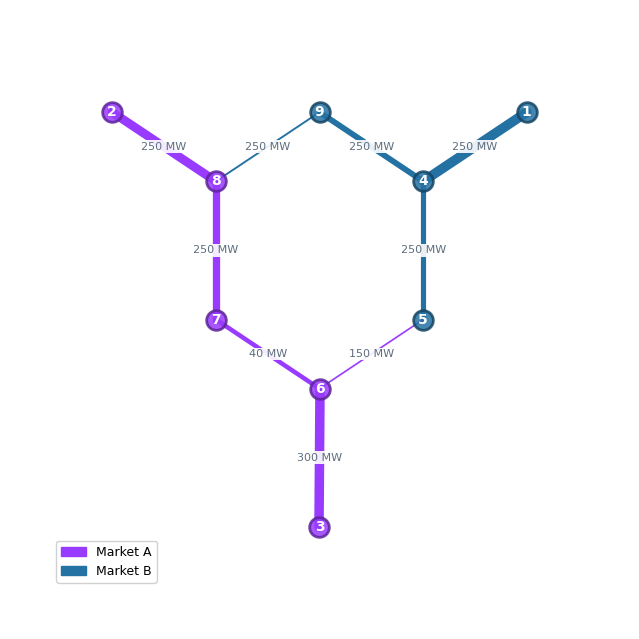

In [6]:
K1 = default_knobs()
CASE1 = build_case(K1)
display(pd.DataFrame(CASE1.fleet).T.rename_axis("unit"))
display(pd.Series(CASE1.loads, name="load (MW)").rename_axis("bus").to_frame())
display(fpmod.line_status_table(CASE1.fp, CASE1.pt, CASE1.monitored, CASE1.activated))
configuration_figure(CASE1.net, CASE1.pt, CASE1.fp, K1["MARKET_COLORS"])
plt.show()

## Example 1. The canonical anchor

At the defaults one market clears both footprints. The footprints named Market A and Market B are its two balancing-authority areas, joined by an unlimited interface. Every line is activated, and `line_4` (6-7) is rated 40 MW. The clearing's congestion rent is \$804.1/h and its signed line dual on `line_4` is $-\$20.10$/MWh. The assert cell checks both against the repository's golden values (`tests/golden/golden.json`).

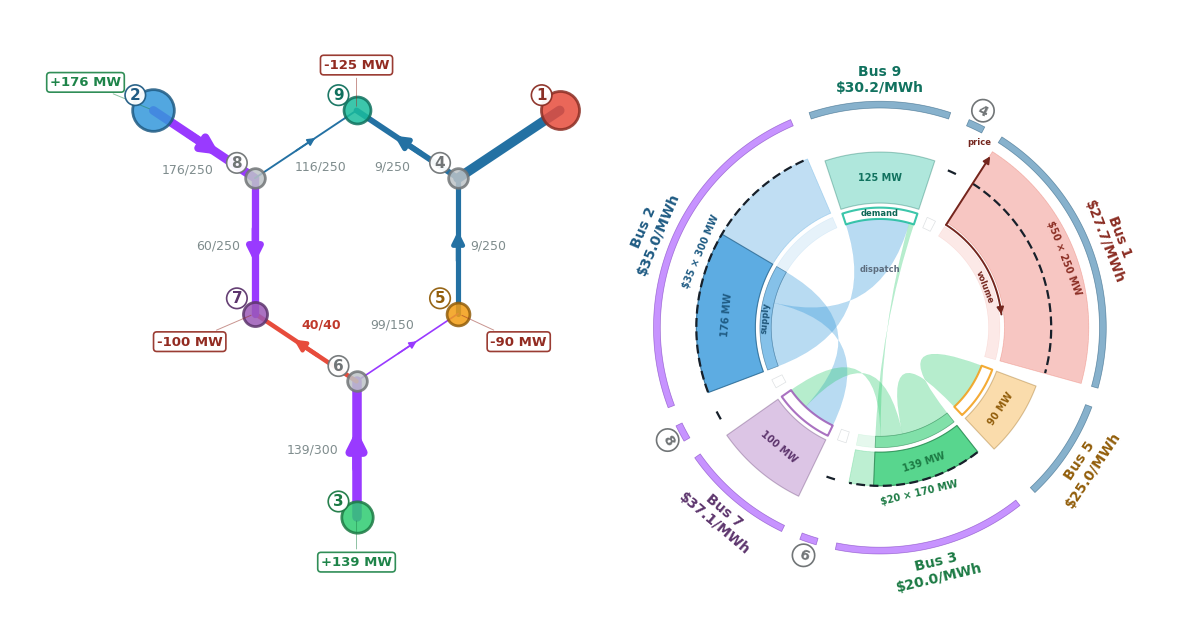

nodal prices ($/MWh):

{'1': 27.74, '2': 35.0, '3': 20.0, '4': 27.74, '5': 25.02, '6': 20.0, '7': 37.13, '8': 35.0, '9': 30.25}

dispatch (MW):

{'gen_slack_0': 0.0, 'gen_0': 176.1, 'gen_1': 138.9}

binding lines ($/MWh):

{'line_4': -20.1024}

transfer, Market A area -> Market B area (MW):

215.0

| area prices ($/MWh):

{'Market A': 27.74, 'Market B': 27.74}

In [7]:
ENG1, RES1 = clear_unified(CASE1)
unified_views(CASE1, ENG1, RES1)
print("nodal prices ($/MWh):", {b: round(RES1.lmp[b], 2) for b in CASE1.pt.buses})
print("dispatch (MW):", {g: round(x, 1) for g, x in RES1.dispatch.items()})
print("binding lines ($/MWh):", {m: round(v, 4) for m, v in RES1.line_dual.items() if abs(v) > TOL})
print("transfer, Market A area -> Market B area (MW):", round(RES1.transfers[IFC], 1),
      "| area prices ($/MWh):", {a: round(v, 2) for a, v in RES1.area_prices.items()})
plt.show()

Line 6-7 binds at 40 MW with $\mu_{\mathrm{line\_4}}=-\$20.10$/MWh. The bus-7 load behind it prices at \$37.13/MWh, buses 3 and 6 at the \$20 offer, and buses 2 and 8 at the \$35 offer. The \$35 unit at bus 2 runs 176.1 MW and the \$20 unit at bus 3 runs 138.9 MW, and the \$50 unit at bus 1 is idle. The Market A area transfers 215 MW to the Market B area, and with the interface unlimited both area energy prices are \$27.74/MWh.

In [8]:
LED1 = unified_ledgers(CASE1, ENG1, RES1)
WALK1 = line_dual_walk(CASE1.pt, ENG1, RES1, "line_4")
print("The line-dual walk of eq. (5) on line_4:")
display(WALK1)

Settlement by node:

,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),paid by load ($/h)
bus,,,,,
1,27.74,0.0,0.0,0.0,0.0
2,35.0,176.1,6162.4,0.0,0.0
3,20.0,138.9,2778.6,0.0,0.0
4,27.74,0.0,0.0,0.0,0.0
5,25.02,0.0,0.0,90.0,2251.8
6,20.0,0.0,0.0,0.0,0.0
7,37.13,0.0,0.0,100.0,3712.6
8,35.0,0.0,0.0,0.0,0.0
9,30.25,0.0,0.0,125.0,3780.8


Marginal value of line capacity (TOTAL = R):

,from,to,flow (MW),rating (MW),binding,|mu| ($/MWh = value of +1 MW),rent |mu| x flow ($/h)
line,,,,,,,
line_0,1,4,-0.0,250.0,False,0.0,0.0
line_1,4,5,-8.9,250.0,False,0.0,0.0
line_2,5,6,-98.9,150.0,False,0.0,0.0
line_3,3,6,138.9,300.0,False,0.0,0.0
line_4,6,7,40.0,40.0,True,20.1,804.1
line_5,7,8,-60.0,250.0,False,0.0,0.0
line_6,8,2,-176.1,250.0,False,0.0,0.0
line_7,8,9,116.1,250.0,False,0.0,0.0
line_8,9,4,-8.9,250.0,False,0.0,0.0


Conservation, eq. (6):

,$/h
"load pays, L ($/h)",9745.1280
"awards pay at bus prices, Q ($/h)",0.0000
"generation is paid, G ($/h)",8941.0335
"fixed injections are paid, X ($/h)",0.0000
L + Q - G - X ($/h),804.0945
R ($/h),804.0945
R_T ($/h),0.0000
pinned transfers at the area-price gap ($/h),0.0000
R^dc ($/h),0.0000
"residual, bus-price form ($/h)",-0.0000


... (11 outputs left out)

Independent operation against the unified clearing, congestion Method 2, transfer method T1:

Market A           Market B              TOTAL
                                                 Consumer Generator Consumer Generator         
Independent operation: payment / revenue          -3712.6    2908.5 -10750.0   10750.0   -804.1
Independent operation: production cost                      -2908.5           -10750.0 -13658.5
Independent operation: own congestion rent (CRR)    804.1                0.0              804.1
Independent operation: position                   -2908.5       0.0 -10750.0       0.0 -13658.5
Constrained: payment / revenue                    -3712.6    8941.0  -6032.5       0.0   -804.1
Constrained: production cost                                -8941.0               -0.0  -8941.0
Congestion rent collected (assigned lines)          804.1                0.0              804.1
Congestion rent allocated (CRR)                    1130.1               69.2             1199.3
Transfer settlement collected                                                            -395.2
Transfer settlement allocated (CRR)                -197.6             -197.6             -395.2
Final position                                    -2780.1       0.0  -6160.9       0.0  -8941.0
Delta vs independent operation                      128.4       0.0   4589.1       0.0   4717.5
Pareto (Delta >= 0)                                   yes       yes      yes       yes

The line-dual walk of eq. (5) on line_4:

,bus,offer ($/MWh),redispatch (MW),cost change ($/h)
unit,,,,
gen_0,2,35.0,1.340157e+00,46.905512
gen_1,3,20.0,-1.340157e+00,-26.803150
TOTAL,,,-4.440892e-16,20.102362


Both settlement tables total $R=\$804.1$/h, and (6) closes. Method 1 gives the whole rent to the Market A area, which holds `line_4`. Both areas hold units, so `HUB_KIND = "auto"` weights each hub by nameplate capacity. Market A's hub price is $(300\cdot\$35+170\cdot\$20)/470=\$29.57$/MWh, and Market B's is the price at bus 1, \$27.74/MWh. The Market A area's congestion by region is \$1,130.08/h and the Market B area's \$69.24/h, against a transfer settlement of $-\$395.22$/h, so (8) closes on $R$. At $\sigma_a=\frac12$ Method 2 gives the Market A area \$932.46/h and the Market B area $-\$128.37$/h.

The walk of (5) moves 1.34 MW from the \$20 unit at bus 3 to the \$35 unit at bus 2 and costs \$20.10/h, the absolute dual of `line_4`.

Against independent operation the unified clearing saves \$4,717.5/h. Under Method 1 the whole \$4,717.5/h goes to the Market B area's consumers. Method 2 moves \$128.4/h of it to the Market A area's consumers. The assert cell also checks that Method 2 and the ledgers follow `HUB_KIND`, and that the shares follow the market names when Market B is listed first.

In [9]:
# The anchor against the golden values (one engine, line_4 at 40 MW), the identities of
# (5), (6), (8) and (9), and the reach of HUB_KIND and of the share dicts.
g_alloc, g_uni = GOLDEN["line4_allocation"], GOLDEN["line4_unified"]
AREA = {"Market A": "BA-1", "Market B": "BA-2"}   # the golden's names for the two areas


def golden_close(got: float, want: float) -> bool:
    """Equal within the golden's relative tolerance, with a 1-unit floor on the scale."""
    return abs(got - want) <= GOLDEN_REL * max(1.0, abs(want))


R1 = ra.constraint_rent(RES1, CASE1.pt)
mu1 = RES1.line_dual["line_4"]
assert golden_close(R1, g_alloc["summary.R"]), R1
assert golden_close(mu1, g_uni["res.line_dual.line_4"]), mu1
for b in CASE1.pt.buses:
    assert golden_close(RES1.lmp[b], g_uni[f"res.lmp.{b}"]), b
alloc1, summ1 = LED1["alloc"], LED1["summ"]
sigma1 = {"Market A": K1["TE_SPLIT"], "Market B": 1.0 - K1["TE_SPLIT"]}
hub_residual1 = float(LED1["eq8"]["residual ($/h)"])
# HUB_KIND "auto": both areas hold units, so each hub is nameplate-weighted
hub_price1 = {a: sum(w * RES1.lmp[b] for b, w in LED1["weights"][a].items())
              for a in AREA}
for a in AREA:
    units_a = [s for s in CASE1.fleet.values() if str(s["bus"]) in K1["MARKETS"][a]]
    gap_a = (sum(float(s["p_nom"]) * RES1.lmp[str(s["bus"])] for s in units_a)
             / sum(float(s["p_nom"]) for s in units_a))
    assert abs(hub_price1[a] - gap_a) <= TOL, a
for a, ga in AREA.items():
    assert golden_close(alloc1.loc[a, "method1"], g_alloc[f"alloc.method1.{ga}"]), a
    assert golden_close(summ1["Nc"][a], g_alloc[f"summary.Nc.{ga}"]), a
    assert abs(alloc1.loc[a, "method2"] - summ1["Nc"][a] - sigma1[a] * summ1["TE"]) <= TOL, a
assert golden_close(summ1["TE"], g_alloc["summary.TE"])
assert abs(alloc1["method2"].sum() - R1 - ra.transfer_rent(RES1)) <= TOL
assert abs(hub_residual1) <= TOL   # eq. (8), unrounded
assert abs(LED1["cons"]["residual, bus-price form ($/h)"]) <= TOL
assert abs(float(WALK1.loc["TOTAL", "cost change ($/h)"]) - abs(mu1)) <= TOL
# HUB_KIND reaches Method 2 and the ledgers: at ELAP hubs both read the hub frame's N^{c,w}.
# The hub frame and the ledger round to 0.1, so they are compared within 0.05.
LED1E = unified_ledgers(build_case(default_knobs() | {"HUB_KIND": "elap"}), ENG1, RES1, show=False)
hub1e, summ1e = LED1E["hub"].loc["Congestion ($/h)"], LED1E["summ"]
diff_e = max(abs(LED1E["alloc"].loc[a, "method2"] - summ1e["Nc"][a] - sigma1[a] * summ1e["TE"])
             for a in AREA)
led_e = float(LED1E["ledgers"][(2, 1)].loc["Congestion rent allocated (CRR)",
                                           ("Market A", "Consumer")])
assert diff_e <= TOL
for a in AREA:
    assert abs(summ1e["Nc"][a] - float(hub1e[a])) <= 0.05 + 1e-9, a
assert abs(summ1e["TE"] - float(hub1e["Transfer (hub-to-hub)"])) <= 0.05 + 1e-9
assert abs(led_e - summ1e["Nc"]["Market A"]) <= 0.05 + 1e-9
assert abs(summ1e["Nc"]["Market A"] - summ1["Nc"]["Market A"]) > 1.0   # the hub moved
# The shares follow the names: with Market B listed first, TE_SPLIT 0.3 still goes to Market A.
K1R = default_knobs() | {"MARKETS": {"Market B": ["1", "9", "4", "5"],
                                     "Market A": ["2", "8", "7", "6", "3"]},
                         "TE_SPLIT": 0.3, "CONGESTION_METHODS": []}
LED1R = unified_ledgers(build_case(K1R), ENG1, RES1, show=False)
m2r = LED1R["alloc"].loc["Market A", "method2"]
assert abs(m2r - LED1R["summ"]["Nc"]["Market A"] - 0.3 * LED1R["summ"]["TE"]) <= TOL
t1 = RES1.transfers[IFC]
assert abs(t1 - (sum(RES1.gen_by_bus.get(b, 0.0) for b in K1["MARKETS"]["Market A"])
                 - sum(CASE1.loads.get(b, 0.0) for b in K1["MARKETS"]["Market A"]))) <= TOL
pd.Series({"R ($/h)": R1, "golden R ($/h)": g_alloc["summary.R"],
           "mu_line_4 ($/MWh)": mu1, "golden mu_line_4 ($/MWh)": g_uni["res.line_dual.line_4"],
           "transfer t (MW)": t1, "walk cost ($/h)": float(WALK1.loc["TOTAL", "cost change ($/h)"]),
           "conservation residual ($/h)": LED1["cons"]["residual, bus-price form ($/h)"],
           "eq. (8) residual ($/h)": hub_residual1,
           "hub price, Market A ($/MWh)": hub_price1["Market A"],
           "hub price, Market B ($/MWh)": hub_price1["Market B"],
           "ELAP: Method 2 less N^cw + sigma T_E, max ($/h)": diff_e,
           "ELAP: ledger Method 2 congestion, Market A ($/h)": led_e,
           "ELAP: Method 2's N^cw, Market A ($/h)": summ1e["Nc"]["Market A"],
           "ELAP: hub-frame N^cw, Market A ($/h)": float(hub1e["Market A"]),
           "Market B first, TE_SPLIT 0.3: A's Method 2 ($/h)": m2r},
          name="Example 1, asserted").round(4).to_frame()

,"Example 1, asserted"
R ($/h),804.0945
golden R ($/h),804.0945
mu_line_4 ($/MWh),-20.1024
golden mu_line_4 ($/MWh),-20.1024
transfer t (MW),215.0000
walk cost ($/h),20.1024
conservation residual ($/h),-0.0000
eq. (8) residual ($/h),-0.0000
"hub price, Market A ($/MWh)",29.5745
"hub price, Market B ($/MWh)",27.7362


## Example 2. Two markets and a scheduling point at bus 8

The same knobs with `MODE = "two markets"` and `SCHED_POINT = {"market": "Market A", "bus": "8", "limit_mw": 100.0}`. Market A clears its own resources against its own load, with Market B's willingness to pay as export bids at bus 8 and an intertie scheduling limit of 100 MW on their awards. Market B then clears its own book with the awards entering at bus 8 as a fixed injection. Bus 8 is Market A's end of the 8-9 tie and carries no resource.

Market B's willingness to pay at bus 8 is expected to be one block at its \$50 offer. The awards then stop at the limit, the block is awarded in part, and by (7) $\mu^s$ is \$50 less Market A's price at bus 8. The export resource's price $\lambda_8+\mu^s$ then equals Market B's own price at bus 8, and Market A's book keeps the anchor's binding `line_4`. The expectation is confirmed if six checks hold. The awards equal the limit. $\mu^s$ equals the bid less $\lambda_8$ within $10^{-6}$. $\lambda_8+\mu^s$ equals Market B's price at bus 8. $R^{\mathrm{ISL}}=\mu^s\sum_{j\in J_s}q_j$. Both forms of (7) close within $10^{-6}$ in Market A. Eq. (6) closes in Market B. The expectation is refuted if any check fails.

In [10]:
K2 = default_knobs()
K2["MODE"] = "two markets"
K2["SCHED_POINT"] = {"market": "Market A", "bus": "8", "limit_mw": 100.0}
CASE2 = build_case(K2)
_ENG2U, RES2U = clear_unified(CASE2, trade=False)
TWO2 = clear_two(CASE2, RES2U)
print("Market B's willingness to pay at bus 8, eq. (12):")
display(pd.DataFrame(TWO2["blocks"]).round(4))
RUN2A, RUN2B = TWO2["runs"]["Market A"], TWO2["runs"]["Market B"]
print("Market A's awards (MW):", {i: round(q, 2) for i, q in RUN2A.res.demand_cleared.items()},
      "| mu^s ($/MWh):", round(RUN2A.res.schedule_limit_dual["isl"], 4),
      "| lambda_8 ($/MWh):", round(RUN2A.res.lmp["8"], 4))
print("Market B's fixed injection (MW):", RUN2B.res.exo_by_bus,
      "| Market B's price at bus 8 ($/MWh):", round(RUN2B.res.lmp["8"], 4))

Market B's willingness to pay at bus 8, eq. (12):

,price,mw,from,lmp_mid
0,50.0,215.0,0.0,50.0


Market A's awards (MW):

{'wtp_00': 100.0}

| mu^s ($/MWh):

15.0

... (2 outputs left out)

Market B's fixed injection (MW):

{'8': 100.0}

| Market B's price at bus 8 ($/MWh):

50.0

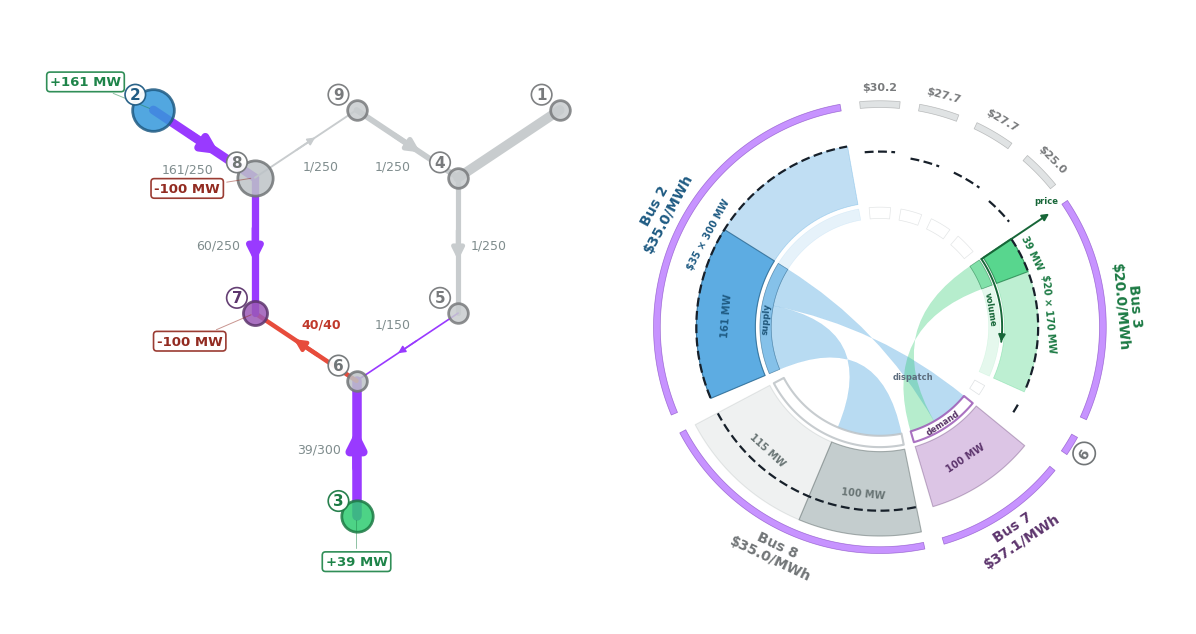

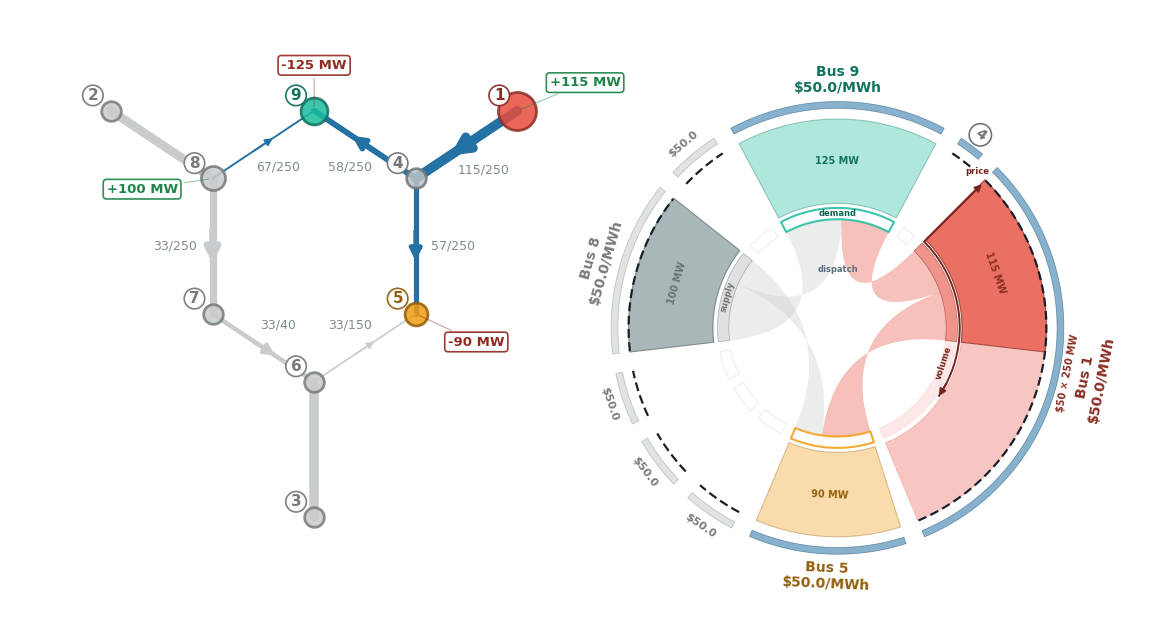

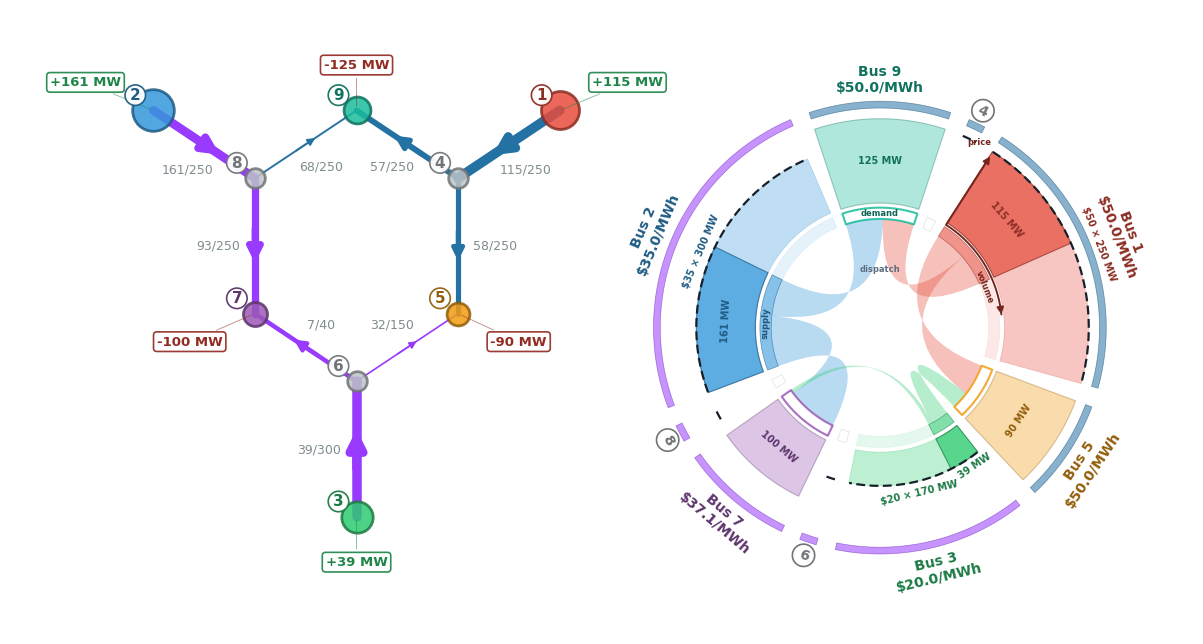

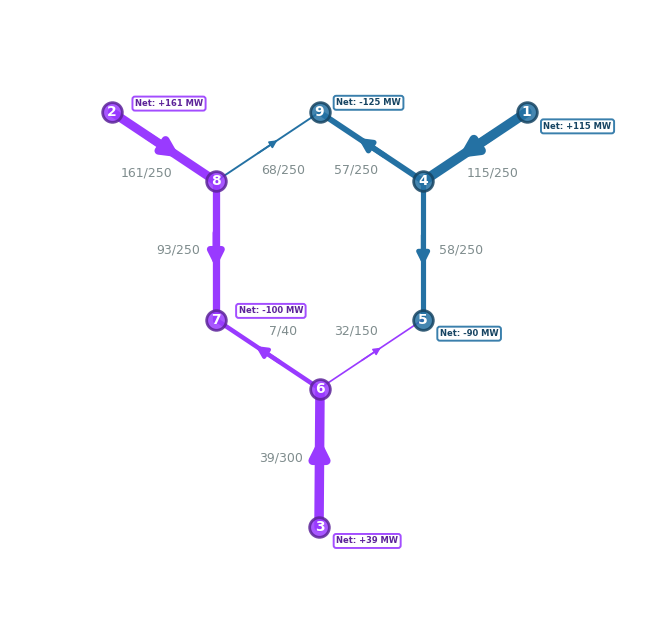

In [11]:
TWO2["pf_view"] = two_market_views(CASE2, TWO2)
plt.show()

The figures show Market A's clearing with Market B's bid in gray at bus 8, Market B's clearing with the 100 MW import in gray at bus 8, and two views of the superposition of (10). Market A's book binds `line_4` at 40 MW with the anchor's dual, $-\$20.10$/MWh, on a dispatch that is not the anchor's. The \$20 unit at bus 3 runs 39.4 MW against 138.9 MW in the anchor, and the \$35 unit at bus 2 runs 160.6 MW against 176.1 MW. `line_4` is the only binding line in both clearings, and the same two units are marginal. By (5), their offers and their shift factors on `line_4` alone fix $\lvert\mu_m\rvert$, so the dual is the anchor's. Market B's \$50 unit runs 115 MW against its 215 MW of load, and every Market B bus prices at \$50/MWh. The superposition places 7.3 MW on line 6-7, where Market A's book enforced 40 MW, and no line is overloaded.

In [12]:
LED2 = two_market_ledgers(CASE2, TWO2, RES2U)
# The same case with the scheduling limit slack, to split the production-cost gap.
K2S = copy.deepcopy(K2)
K2S["SCHED_POINT"]["limit_mw"] = 1000.0
OUT2S = run_chain(K2S, show=False)
COST2 = {}
for label, two, led in (("limit 100 MW", TWO2, LED2),
                        ("limit 1,000 MW", OUT2S["two"], OUT2S["ledgers"])):
    r = two["runs"]["Market A"].res
    COST2[label] = pd.Series(
        {"awards (MW)": sum(r.demand_cleared.values()),
         "mu^s ($/MWh)": r.schedule_limit_dual.get("isl", 0.0),
         "gen_1 at bus 3, Market A (MW)": r.dispatch["gen_1"],
         "gen_0 at bus 2, Market A (MW)": r.dispatch["gen_0"],
         "mu_line_4, Market A ($/MWh)": r.line_dual.get("line_4", 0.0),
         "mu_line_6, Market A ($/MWh)": r.line_dual.get("line_6", 0.0)}
        | led["cost"].to_dict())
COST2 = pd.DataFrame(COST2)
print("Market A's clearing and the production cost, the limit binding and slack:")
display(COST2.round(2))

Settlement by node, Market A (awards at their buses):

,in settlement,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),paid by load ($/h)
bus,,,,,,
1,False,27.74,0.0,0.0,0.0,0.0
2,True,35.0,160.6,5619.8,0.0,0.0
3,True,20.0,39.4,788.7,0.0,0.0
4,False,27.74,0.0,0.0,0.0,0.0
5,False,25.02,0.0,0.0,0.0,0.0
6,True,20.0,0.0,0.0,0.0,0.0
7,True,37.13,0.0,0.0,100.0,3712.6
8,True,35.0,0.0,0.0,100.0,3500.0
9,False,30.25,0.0,0.0,0.0,0.0


Marginal value of line capacity, Market A (TOTAL = R):

,from,to,flow (MW),rating (MW),binding,|mu| ($/MWh = value of +1 MW),rent |mu| x flow ($/h)
line,,,,,,,
line_0,1,4,0.0,250.0,False,0.0,0.0
line_1,4,5,0.6,250.0,False,0.0,0.0
line_2,5,6,0.6,150.0,False,0.0,0.0
line_3,3,6,39.4,300.0,False,0.0,0.0
line_4,6,7,40.0,40.0,True,20.1,804.1
line_5,7,8,-60.0,250.0,False,0.0,0.0
line_6,8,2,-160.6,250.0,False,0.0,0.0
line_7,8,9,0.6,250.0,False,0.0,0.0
line_8,9,4,0.6,250.0,False,0.0,0.0


Conservation, Market A, eqs. (6) and (7):

,$/h
"load pays, L ($/h)",3712.5984
"awards pay at bus prices, Q ($/h)",3500.0000
"generation is paid, G ($/h)",6408.5039
"fixed injections are paid, X ($/h)",0.0000
L + Q - G - X ($/h),804.0945
R ($/h),804.0945
R_T ($/h),0.0000
pinned transfers at the area-price gap ($/h),0.0000
R^dc ($/h),0.0000
"residual, bus-price form ($/h)",0.0000


... (9 outputs left out)

,λ[Market A],λ[Market B],Δλ[Market A→Market B]
bus,,,
1,27.74,50.0,22.26
2,35.00,50.0,15.00
3,20.00,50.0,30.00
4,27.74,50.0,22.26
5,25.02,50.0,24.98
6,20.00,50.0,30.00
7,37.13,50.0,12.87
8,35.00,50.0,15.00
9,30.25,50.0,19.75


,$/h
Market A production cost ($/h),6408.50
Market B production cost ($/h),5750.00
two markets ($/h),12158.50
"unified, no trade objects ($/h)",8941.03
two markets less unified ($/h),3217.47


Market A's clearing and the production cost, the limit binding and slack:

,limit 100 MW,"limit 1,000 MW"
awards (MW),100.00,189.43
mu^s ($/MWh),15.00,0.00
"gen_1 at bus 3, Market A (MW)",39.43,39.43
"gen_0 at bus 2, Market A (MW)",160.57,250.00
"mu_line_4, Market A ($/MWh)",-20.10,-40.20
"mu_line_6, Market A ($/MWh)",0.00,15.00
Market A production cost ($/h),6408.50,9538.66
Market B production cost ($/h),5750.00,1278.35
two markets ($/h),12158.50,10817.01
"unified, no trade objects ($/h)",8941.03,8941.03


In the superposed-flows table, `F[Market A]` and `F[Market B]` are each market's summand of (10), its generation less the load it serves, with the award left out. They are not the markets' own flows $F^M_m$ of (2). Each summand is unbalanced by the award, Market A's by +100 MW and Market B's by −100 MW, so its split across lines depends on the slack at bus 1, and only the sum $F^s_m$ is slack-invariant. With the slack at bus 1, Market A's summand on `line_4` is 3.9 MW, and its own flow, which carries the award as a withdrawal at bus 8 and does not depend on the slack, is 40 MW.

The awards stop at the 100 MW limit. Market A's price at bus 8 is \$35/MWh, the \$35 unit's offer, so $\mu^s=\$15$/MWh and $R^{\mathrm{ISL}}=\$1{,}500$/h, reported in Market A, which declares the limit. Market A's settlement at bus prices closes on its $R=\$804.1$/h, and at the export resource's price it closes on $R+R^{\mathrm{ISL}}$.

Market B's settlement closes with $R=0$, the import credited \$5,000/h at its \$50 price. The two markets' production cost is \$12,158.50/h against \$8,941.03/h for the unified clearing of the same case, \$3,217.47/h more.

With the limit at 1,000 MW, $\mu^s=0$, the awards are 189.43 MW and the gap is \$1,875.97/h. The 100 MW limit accounts for \$1,341.50/h of the \$3,217.47/h gap. Market A's book enforces line 6-7 on its own flow, with the export withdrawn at bus 8 in place of Market B's loads at buses 5 and 9. Line 6-7 then binds with the \$20 unit at bus 3 at 39.43 MW, against 138.9 MW in the unified clearing. With the limit slack, line 8-2 also binds at its 250 MW rating, with the \$35 unit at bus 2 at 250 MW. The two binding lines stop the awards at 189.43 MW.

In [13]:
# Example 2's reading rule, asserted.
rA, rB = RUN2A.res, RUN2B.res
q_bar = K2["SCHED_POINT"]["limit_mw"]
sp = K2["SCHED_POINT"]["bus"]
q2 = sum(rA.demand_cleared.values())
mu_s2 = rA.schedule_limit_dual["isl"]
partial2 = [b for b in RUN2A.bids if TOL < rA.demand_cleared.get(b["id"], 0.0) < b["mw"] - TOL]
b_units = [s for s in CASE2.fleet.values() if str(s["bus"]) in K2["MARKETS"]["Market B"]]
d_b = sum(CASE2.loads.get(b, 0.0) for b in K2["MARKETS"]["Market B"])
assert len(TWO2["blocks"]) == 1 and abs(TWO2["blocks"][0]["mw"] - d_b) <= TOL   # one block, B's whole load
assert abs(TWO2["blocks"][0]["price"] - min(s["cost"] for s in b_units)) <= TOL   # at B's own offer
assert abs(q2 - q_bar) <= TOL
assert len(partial2) == 1
assert abs(mu_s2 - (partial2[0]["price"] - rA.lmp[sp])) <= TOL
assert abs(rA.lmp[sp] + mu_s2 - rB.lmp[sp]) <= TOL
q_s2 = sum(rA.demand_cleared.get(j, 0.0) for j in RUN2A.isl[0])   # the awards J_s names
assert abs(isl_rent(rA) - mu_s2 * q_s2) <= TOL   # eq. (7)
consA, consB = LED2["cons"]["Market A"], LED2["cons"]["Market B"]
assert abs(consA["residual, bus-price form ($/h)"]) <= TOL
assert abs(consA["residual, resource-price form ($/h)"]) <= TOL
assert abs(consB["residual, bus-price form ($/h)"]) <= TOL
assert golden_close(rA.line_dual["line_4"], GOLDEN["line4_unified"]["res.line_dual.line_4"])
assert abs(rB.exo_by_bus[sp] - q2) <= TOL
assert not TWO2["pf"]["overload"].any()
# F[Market A] is Market A's summand of (10): generation less served load, award left out.
# The flow table rounds to 0.1 MW, so it is compared within 0.05.
inj2a = np.array([rA.gen_by_bus.get(b, 0.0) - float(RUN2A.eng.loads.get(b, 0.0))
                  + rA.shed_by_bus.get(b, 0.0) for b in CASE2.pt.buses])
f_sum2a = float((CASE2.pt.ptdf @ inj2a)[CASE2.pt.line_idx["line_4"]])
assert abs(f_sum2a - float(TWO2["pf"].loc["line_4", "F[Market A]"])) <= 0.05 + 1e-9
# The own flow less the summand is the award withdrawn at bus 8 and delivered to the slack.
sf_sp4 = CASE2.pt.ptdf[CASE2.pt.line_idx["line_4"], CASE2.pt.bus_idx[str(sp)]]
assert abs(rA.flow_own["line_4"] - f_sum2a - (-q2) * sf_sp4) <= 0.05 + 1e-9
# Only the sum of the two summands, F^s, is slack-invariant.
assert abs(float(TWO2["pf"].loc["line_4", "F[Market A]"])
           + float(TWO2["pf"].loc["line_4", "F[Market B]"])
           - float(TWO2["pf"].loc["line_4", "F_phys"])) <= 0.1
c2, c2s = COST2["limit 100 MW"], COST2["limit 1,000 MW"]
gap2 = c2["two markets less unified ($/h)"]
gap2s = c2s["two markets less unified ($/h)"]
assert abs(c2s["mu^s ($/MWh)"]) <= TOL and c2s["awards (MW)"] < 1000.0 - TOL
assert abs(c2["gen_1 at bus 3, Market A (MW)"] - c2s["gen_1 at bus 3, Market A (MW)"]) <= TOL
assert abs(round(gap2, 2) - 3217.47) <= 0.005 and abs(round(gap2s, 2) - 1875.97) <= 0.005
pd.Series({"awards (MW)": q2, "limit (MW)": q_bar, "lambda_8 ($/MWh)": rA.lmp[sp], "mu^s ($/MWh)": mu_s2,
           "marginal bid ($/MWh)": partial2[0]["price"],
           "export resource price ($/MWh)": rA.lmp[sp] + mu_s2,
           "Market B's price at bus 8 ($/MWh)": rB.lmp[sp], "R^ISL ($/h)": isl_rent(rA),
           "R, Market A ($/h)": ra.constraint_rent(rA, RUN2A.pt),
           "mu_line_4, Market A ($/MWh)": rA.line_dual["line_4"],
           "F^s line_4 (MW)": float(TWO2["pf"].loc["line_4", "F_phys"]),
           "Market A book flow line_4 (MW)": rA.flow_own["line_4"],
           "Market A summand of (10), line_4 (MW)": f_sum2a,
           "cost gap, limit binding ($/h)": gap2, "cost gap, limit slack ($/h)": gap2s,
           "cost gap from the limit ($/h)": gap2 - gap2s},
          name="Example 2, asserted").round(4).to_frame()

,"Example 2, asserted"
awards (MW),100.0000
limit (MW),100.0000
lambda_8 ($/MWh),35.0000
mu^s ($/MWh),15.0000
marginal bid ($/MWh),50.0000
export resource price ($/MWh),50.0000
Market B's price at bus 8 ($/MWh),50.0000
R^ISL ($/h),1500.0000
"R, Market A ($/h)",804.0945
"mu_line_4, Market A ($/MWh)",-20.1024


**The scheduling limit against the golden.** The golden values hold this scheduling-limit clearing at the base ratings (`isl`) with nothing derated. The scheduling point is bus 9, Market B's end of the 8-9 tie, and it is carried in Market A's balance. The cell below runs the chain on that configuration without its figures and asserts the dual, the awards, Market A's production cost and its price at bus 9 against them.

In [14]:
K3 = default_knobs()
K3["MODE"] = "two markets"
K3["LINE_RATINGS"] = {}
K3["SCHED_POINT"] = {"market": "Market A", "bus": "9", "limit_mw": 100.0}
OUT3 = run_chain(K3, show=False)
r3 = OUT3["two"]["runs"]["Market A"].res
g_isl = GOLDEN["scheduling_limit"]
checks3 = {"mu^s ($/MWh)": (r3.schedule_limit_dual["isl"], g_isl["isl_dual.isl"]),
           "awards (MW)": (sum(r3.demand_cleared.values()), g_isl["isl_awards.imp_0"]),
           "Market A production cost ($/h)": (r3.total_cost, g_isl["isl.total_cost"]),
           "lambda_9 ($/MWh)": (r3.lmp["9"], g_isl["isl.lmp.9"]),
           "block MW": (OUT3["two"]["blocks"][0]["mw"], g_isl["bids[0].mw"]),
           "block price ($/MWh)": (OUT3["two"]["blocks"][0]["price"], g_isl["bids[0].price"])}
for name, (got, want) in checks3.items():
    assert golden_close(got, want), (name, got, want)
pd.DataFrame(checks3, index=["sandbox", "golden"]).T

,sandbox,golden
mu^s ($/MWh),15.0,15.0
awards (MW),100.0,100.0
Market A production cost ($/h),4450.0,4450.0
lambda_9 ($/MWh),35.0,35.0
block MW,215.0,215.0
block price ($/MWh),50.0,50.0


## Sandbox

The cell below reruns the whole chain of this notebook on the knobs the EDIT cell sets. At the defaults it repeats Example 1. The sandbox carries the following limits.

1. It clears one period, energy only, on a lossless DC network, with no commitment, reserves or ramping. Multi-period clearing, storage, the stochastic lookahead and sequential pricing are not carried.
2. A rising offer cleared as a curve (`OFFER_MODE = "curves"`) excludes the bids, the scheduling limit, pinned transfers, must-run, the VRL and HVDC links, and the engine raises on the combination. The scheduling limit with rising offers takes `"tranches"`.
3. The scheduling limit caps export awards entered as demand bids, gross and one-sided. An import-direction limit on import offers has no form here.
4. $\mu^s$ never enters $\lambda_n$, and $R^{\mathrm{ISL}}$ sits outside $R$ and $R_T$, so a settlement at $\lambda_n$ does not collect it.
5. Bids, offers and the scheduling point sit in one market at a time, because the second market clears on the first market's awards. A price-sensitive bid in the second market, or in both, has no sequential form here.
6. In two-markets mode the engines carry one area each and no interface, so `INTERFACES`, `FIXED_TRANSFERS`, `INTERFACE_VRL`, `DC_LINKS` and `FLOWGATES` enter only the unified clearing, which in that mode is the production-cost benchmark and the $\psi$ reference.
7. A one-sided fixed injection in two-markets mode leaves the superposition unbalanced, and `physical_flows` raises on it. A schedule between the two markets is entered as a self-schedule.
8. The bid under a continuous curve awarded by bisection, the day-ahead to real-time chain with offsets and two settlements, and the loading-relief reconciliation by backstop or by market flow limit are not carried. The real-time relief re-clears at flat offers.
9. The fleet field `p_min` is not read, and the must-run floor is `GEN_MIN`.
10. Tags and the loading relief apply only to a market whose book carries no award and no fixed injection.
11. Balancing authorities nested inside a market, the ATC, TTC and rights books, the CRR auction, the N-1 de-rate and its LODF reservation, and the risk and certainty-equivalent layer are not exposed.
12. Eq. (8) and Method 2 read the net withdrawal $d_n-g_n$. With `SELF_SCHEDULES`, `FIXED_INJECTIONS` or `EXPORT_BIDS` set in unified mode, (8) stays open by $\sum_n\lambda_n\,\mathrm{exo}_n-\sum_j\lambda_{\mathrm{bus}(j)}q_j$, Method 2 allocates that amount with the rent, and the ledgers print the residual.
13. The independent-operation ledgers split $R^{\mathrm u}$ in halves whatever `UNASSIGNED_SPLIT` sets.
14. The independent-operation ledgers clear each area on the case's fleet, loads and ratings only. They omit `SELF_SCHEDULES`, `EXPORT_BIDS`, `IMPORT_OFFERS`, `GEN_MIN`, `DC_LINKS`, `FLOWGATES`, `FIXED_TRANSFERS` and the `"Unified"` entry of `FIXED_INJECTIONS`, and with any of these set in unified mode the chain skips them and prints a notice.
15. The drawing layout is fixed to the 9-bus ring. A change of partition recolors the figures and keeps the layout.

Each market's line sets (enforces = activated, monitors = monitored only):

,ends,location,Market A,Market B
line,,,,
line_0,1-4,internal Market B,--,enforces
line_1,4-5,internal Market B,--,enforces
line_2,5-6,intertie,enforces,--
line_3,3-6,internal Market A,enforces,--
line_4,6-7,internal Market A,enforces,--
line_5,7-8,internal Market A,enforces,--
line_6,8-2,internal Market A,enforces,--
line_7,8-9,intertie,--,enforces
line_8,9-4,internal Market B,--,enforces


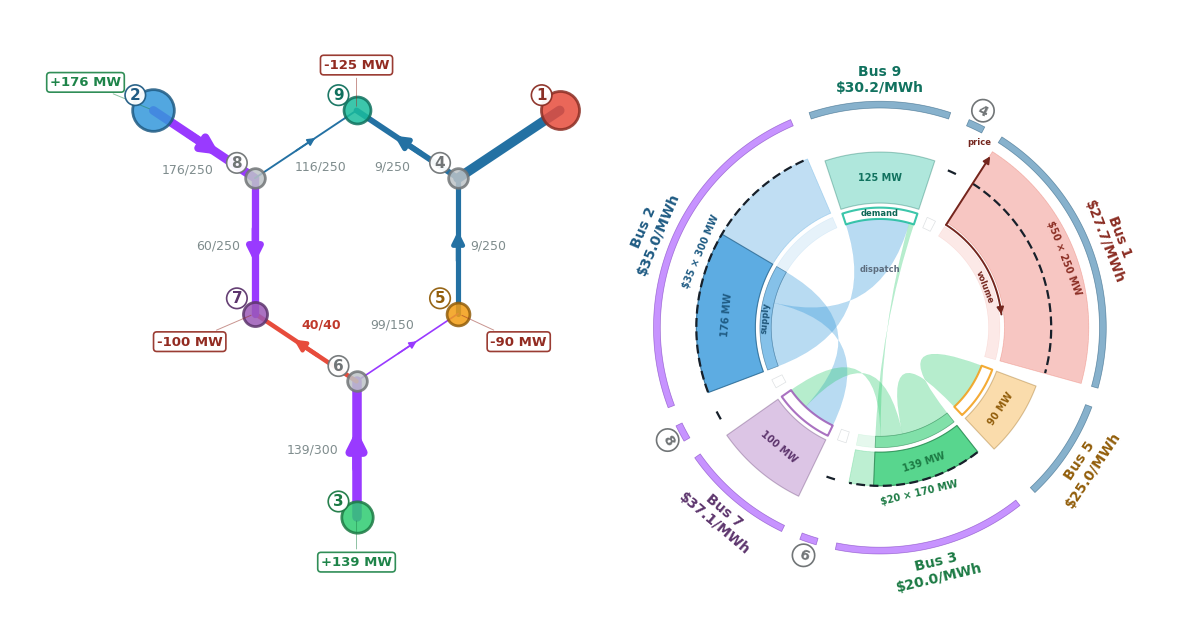

Settlement by node:

,LMP ($/MWh),gen (MW),paid to gen ($/h),load (MW),paid by load ($/h)
bus,,,,,
1,27.74,0.0,0.0,0.0,0.0
2,35.0,176.1,6162.4,0.0,0.0
3,20.0,138.9,2778.6,0.0,0.0
4,27.74,0.0,0.0,0.0,0.0
5,25.02,0.0,0.0,90.0,2251.8
6,20.0,0.0,0.0,0.0,0.0
7,37.13,0.0,0.0,100.0,3712.6
8,35.0,0.0,0.0,0.0,0.0
9,30.25,0.0,0.0,125.0,3780.8


Marginal value of line capacity (TOTAL = R):

,from,to,flow (MW),rating (MW),binding,|mu| ($/MWh = value of +1 MW),rent |mu| x flow ($/h)
line,,,,,,,
line_0,1,4,-0.0,250.0,False,0.0,0.0
line_1,4,5,-8.9,250.0,False,0.0,0.0
line_2,5,6,-98.9,150.0,False,0.0,0.0
line_3,3,6,138.9,300.0,False,0.0,0.0
line_4,6,7,40.0,40.0,True,20.1,804.1
line_5,7,8,-60.0,250.0,False,0.0,0.0
line_6,8,2,-176.1,250.0,False,0.0,0.0
line_7,8,9,116.1,250.0,False,0.0,0.0
line_8,9,4,-8.9,250.0,False,0.0,0.0


Conservation, eq. (6):

,$/h
"load pays, L ($/h)",9745.1280
"awards pay at bus prices, Q ($/h)",0.0000
"generation is paid, G ($/h)",8941.0335
"fixed injections are paid, X ($/h)",0.0000
L + Q - G - X ($/h),804.0945
R ($/h),804.0945
R_T ($/h),0.0000
pinned transfers at the area-price gap ($/h),0.0000
R^dc ($/h),0.0000
"residual, bus-price form ($/h)",-0.0000


... (9 outputs left out)

Independent operation against the unified clearing, congestion Method 1, transfer method T1:

Market A           Market B              TOTAL
                                                 Consumer Generator Consumer Generator         
Independent operation: payment / revenue          -3712.6    2908.5 -10750.0   10750.0   -804.1
Independent operation: production cost                      -2908.5           -10750.0 -13658.5
Independent operation: own congestion rent (CRR)    804.1                0.0              804.1
Independent operation: position                   -2908.5       0.0 -10750.0       0.0 -13658.5
Constrained: payment / revenue                    -3712.6    8941.0  -6032.5       0.0   -804.1
Constrained: production cost                                -8941.0               -0.0  -8941.0
Congestion rent collected (assigned lines)          804.1                0.0              804.1
Congestion rent allocated (CRR)                     804.1                0.0              804.1
Transfer settlement collected                                                               0.0
Transfer settlement allocated (CRR)                   0.0                0.0                0.0
Final position                                    -2908.5       0.0  -6032.5       0.0  -8941.0
Delta vs independent operation                        0.0       0.0   4717.5       0.0   4717.5
Pareto (Delta >= 0)                                   yes       yes      yes       yes

Independent operation against the unified clearing, congestion Method 2, transfer method T1:

Market A           Market B              TOTAL
                                                 Consumer Generator Consumer Generator         
Independent operation: payment / revenue          -3712.6    2908.5 -10750.0   10750.0   -804.1
Independent operation: production cost                      -2908.5           -10750.0 -13658.5
Independent operation: own congestion rent (CRR)    804.1                0.0              804.1
Independent operation: position                   -2908.5       0.0 -10750.0       0.0 -13658.5
Constrained: payment / revenue                    -3712.6    8941.0  -6032.5       0.0   -804.1
Constrained: production cost                                -8941.0               -0.0  -8941.0
Congestion rent collected (assigned lines)          804.1                0.0              804.1
Congestion rent allocated (CRR)                    1130.1               69.2             1199.3
Transfer settlement collected                                                            -395.2
Transfer settlement allocated (CRR)                -197.6             -197.6             -395.2
Final position                                    -2780.1       0.0  -6160.9       0.0  -8941.0
Delta vs independent operation                      128.4       0.0   4589.1       0.0   4717.5
Pareto (Delta >= 0)                                   yes       yes      yes       yes

In [15]:
SANDBOX = run_chain(edit_knobs())
plt.show()